[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch05_Lab05_2026_Activation_Functions_with_outputs.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 5: Activation Functions: Every One, and When** (Part II: Making It Learn). Also used in Chapter 9.

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=5](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=5)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab 05 — Activation Functions

**Neural Networks & Deep Learning Lab · 2026**
*Follows Lab 03 (Backpropagation & the Chain Rule)*

---

### Why this lab exists

In Lab 03 you pushed gradients backwards by hand and saw that every layer
contributes a **local derivative** to the chain-rule product. The activation
function *is* that local derivative. Choose it badly and the product collapses
to zero (nothing learns) or the units switch off permanently (capacity is
wasted). Choose it well and a 50-layer network trains.

This notebook treats four functions — **sigmoid, tanh, ReLU, softmax** — not as
formulas to memorise but as **engineering components with datasheets**: range,
derivative, saturation behaviour, failure modes, and a recommended operating
region.

### Learning outcomes

By the end you will be able to:

1. State each function, its derivative, and its output range from memory.
2. **Explain numerically** why sigmoid causes vanishing gradients and ReLU does not.
3. Diagnose *dying ReLU* and *saturation* from an activation histogram.
4. Implement a **numerically stable** sigmoid and softmax, and say why the naive
   version breaks.
5. Pick the right output-layer activation for binary / multi-class / multi-label /
   regression problems — and justify it.

### Contents

| § | Topic | Key artefact |
|---|-------|--------------|
| 1 | Why we need a non-linearity at all | linear-collapse proof, decision boundaries |
| 2 | **Sigmoid** — the historical default | saturation map, vanishing-gradient product |
| 3 | **Tanh** — sigmoid, zero-centred | `tanh(x) = 2σ(2x) − 1` verified |
| 4 | **ReLU** — the modern workhorse | dying-ReLU counter, ReLU family |
| 5 | **Softmax** — the output-layer specialist | temperature, Jacobian, stability |
| 6 | Head-to-head: gradient flow through depth | the plot that decides the argument |
| 7 | Decision guide — where to use / where **not** to | cheat sheet |
| 8 | Exercises | — |

> **How to run:** top to bottom, `Runtime → Run all`. Pure NumPy + Matplotlib +
> scikit-learn. No GPU, no downloads, ~15 s total.

> ### ✅ Checked edition (November 2026)
> This notebook was re-run top to bottom and checked for *The Why Book of Deep Learning, Part 1*. What changed from the original:
>
> * **Sigmoid datasheet:** the output was called a "calibrated probability". It lies in (0, 1) and *reads* as a probability, but calibration depends on the data and training, not on the function.
> * **§6.2 now matches its own printout.** The text said tanh "still decays", but the measured ratio is about 1× (flat). The new paragraph explains why, using the notebook's own §6.3 numbers: Xavier-initialised tanh units drift towards x ≈ 0, where the average slope is 0.97; with weights 10× too large it falls to 0.08. Exercise E2 was rewritten to match.
> * **ReLU as an output layer:** for non-negative regression the guide now recommends softplus first. A ReLU output that goes negative passes back zero gradient and can stick at 0.
> * §4.3 wording: dead units climb first and accuracy collapses later (at lr = 10, 27% of units are dead and accuracy is still 97%).
> * The cheat-sheet card and the footer said "Lab 04"; they now say Lab 05. (`Lab04_Activation_Functions_with_outputs.ipynb` was an earlier copy of this notebook and is not repeated in this set.)

## 0 · Setup

One cell: imports, a consistent colour assignment (one hue per activation, held
fixed for the whole notebook so a curve's identity never changes between plots),
and the four functions with their analytic derivatives.

Note the **numerically stable `sigmoid`** — the textbook `1/(1+exp(-x))`
overflows for large negative `x`. We fix it here and revisit the same idea for
softmax in §5.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

np.set_printoptions(precision=4, suppress=True, linewidth=110)

# ---------------------------------------------------------------- palette ---
# One hue per activation, fixed for the whole notebook.
# (Validated for colour-vision deficiency: worst pair ΔE 9.2 deutan.)
C = {
    "sigmoid": "#2a78d6",   # blue
    "tanh":    "#eb6834",   # orange
    "relu":    "#1baf7a",   # aqua
    "softmax": "#4a3aa7",   # violet
}
GRID, INK, MUTE, BAD = "#e6e5e1", "#0b0b0b", "#52514e", "#e34948"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": MUTE, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": MUTE, "ytick.color": MUTE,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False, "lines.linewidth": 2.0,
})

def style(ax, title=None, xlabel="x", ylabel=None, zero=True):
    if title:  ax.set_title(title, loc="left", pad=8)
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    if zero:                                  # draw the x=0 / y=0 reference axes
        ax.axhline(0, color=MUTE, lw=0.8, zorder=1)
        ax.axvline(0, color=MUTE, lw=0.8, zorder=1)
    return ax

# ------------------------------------------------------------- functions ---
def sigmoid(x):
    '''Numerically stable logistic sigmoid. sigma(x) = 1 / (1 + e^-x).'''
    x = np.asarray(x, dtype=float)
    out = np.empty_like(x)
    pos = x >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-x[pos]))
    ex = np.exp(x[~pos])                 # e^x is safe when x < 0
    out[~pos] = ex / (1.0 + ex)
    return out

def d_sigmoid(x):
    s = sigmoid(x)
    return s * (1.0 - s)                 # sigma' = sigma (1 - sigma)

def tanh(x):
    return np.tanh(x)

def d_tanh(x):
    return 1.0 - np.tanh(x) ** 2         # tanh' = 1 - tanh^2

def relu(x):
    return np.maximum(0.0, x)

def d_relu(x):
    return (np.asarray(x) > 0).astype(float)   # undefined at 0; convention: 0

def softmax(z, axis=-1):
    '''Numerically stable softmax over `axis`.'''
    z = np.asarray(z, dtype=float)
    z = z - z.max(axis=axis, keepdims=True)     # shift-invariance (see 5.3)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

X = np.linspace(-6, 6, 1201)   # shared plotting grid
print("setup complete ·", "numpy", np.__version__)

setup complete · numpy 2.4.6


---
## 1 · Why a non-linearity at all?

### 1.1 The collapse theorem

Stack $L$ affine layers with **no** activation between them:

$$\mathbf{h}_1 = W_1\mathbf{x} + \mathbf{b}_1,\quad
  \mathbf{h}_2 = W_2\mathbf{h}_1 + \mathbf{b}_2,\quad \dots$$

Substituting gives

$$\mathbf{h}_L = \underbrace{(W_L \cdots W_2 W_1)}_{\displaystyle W_{\text{eff}}}\mathbf{x}
   \;+\; \underbrace{\mathbf{b}_{\text{eff}}}_{\text{one vector}}$$

A composition of affine maps is a **single affine map**. A 100-layer network with
no activation has exactly the representational power of one `Dense` layer — it
can only ever draw a straight decision boundary. Depth buys nothing.

The activation function is the *only* thing that makes depth worth having.

> **Lab 03 link:** the chain rule multiplies one Jacobian per layer. Without an
> activation, every Jacobian is a constant matrix $W_\ell$ — nothing depends on
> the input, so nothing can bend.

In [2]:
# --- 1.1 Numerical proof: three linear layers == one linear layer -----------
rng = np.random.default_rng(0)
W1, b1 = rng.normal(size=(8, 4)),  rng.normal(size=8)
W2, b2 = rng.normal(size=(6, 8)),  rng.normal(size=6)
W3, b3 = rng.normal(size=(3, 6)),  rng.normal(size=3)
x = rng.normal(size=4)

deep   = W3 @ (W2 @ (W1 @ x + b1) + b2) + b3          # 3 layers, no activation
W_eff  = W3 @ W2 @ W1                                  # collapsed weight
b_eff  = W3 @ (W2 @ b1 + b2) + b3                      # collapsed bias
single = W_eff @ x + b_eff                             # ONE layer

print('3-layer output :', deep)
print('1-layer output :', single)
print('max |difference|:', np.abs(deep - single).max())
print('identical      :', np.allclose(deep, single))
print()
print('W_eff shape', W_eff.shape, '-> the whole "deep" net is a 4->3 linear map.')

3-layer output : [14.8381 13.9852  5.9509]
1-layer output : [14.8381 13.9852  5.9509]
max |difference|: 5.329070518200751e-15
identical      : True

W_eff shape (3, 4) -> the whole "deep" net is a 4->3 linear map.


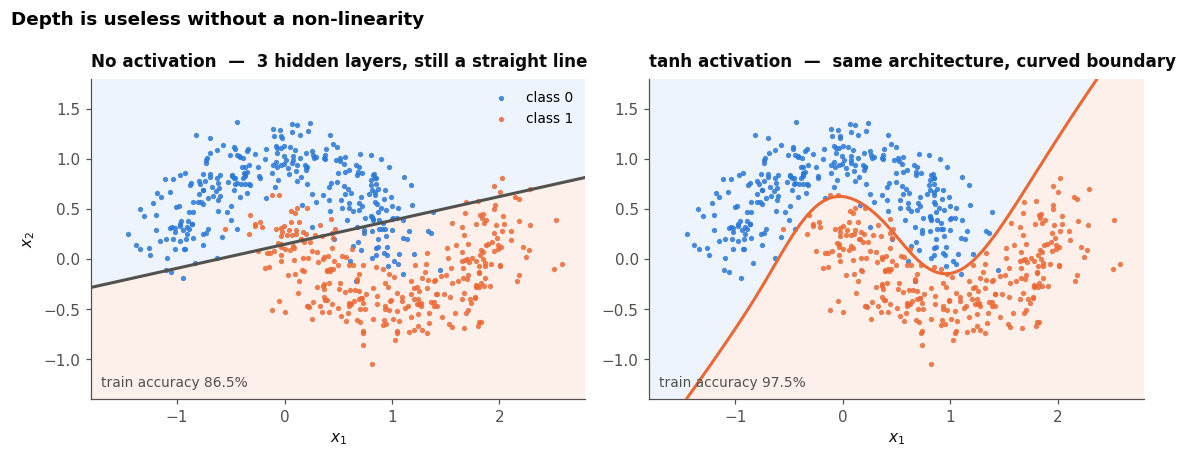

In [3]:
# --- 1.2 What that looks like: same network, activation off vs on ----------
from sklearn.datasets import make_moons
from sklearn.neural_network import MLPClassifier

Xm, ym = make_moons(n_samples=600, noise=0.20, random_state=1)
gx, gy = np.meshgrid(np.linspace(-1.8, 2.8, 320), np.linspace(-1.4, 1.8, 320))
grid   = np.c_[gx.ravel(), gy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for ax, act, title, col in [
        (axes[0], 'identity', 'No activation  —  3 hidden layers, still a straight line', MUTE),
        (axes[1], 'tanh',     'tanh activation  —  same architecture, curved boundary', C['tanh'])]:
    clf = MLPClassifier(hidden_layer_sizes=(32, 32, 32), activation=act,
                        max_iter=3000, random_state=0, alpha=1e-3).fit(Xm, ym)
    zz = clf.predict_proba(grid)[:, 1].reshape(gx.shape)
    ax.contourf(gx, gy, zz, levels=[0, .5, 1], colors=['#eef4fd', '#fdefe9'], zorder=0)
    ax.contour(gx, gy, zz, levels=[.5], colors=[col], linewidths=2, zorder=3)
    ax.scatter(*Xm[ym == 0].T, s=12, c=C['sigmoid'], lw=0, alpha=.85, zorder=2, label='class 0')
    ax.scatter(*Xm[ym == 1].T, s=12, c=C['tanh'],    lw=0, alpha=.85, zorder=2, label='class 1')
    ax.set_title(title, loc='left', pad=8)
    ax.set_xlabel('$x_1$'); ax.grid(False)
    ax.text(.02, .04, f'train accuracy {clf.score(Xm, ym):.1%}',
            transform=ax.transAxes, color=MUTE, fontsize=9)
axes[0].set_ylabel('$x_2$'); axes[0].legend(loc='upper right', fontsize=9)
fig.suptitle('Depth is useless without a non-linearity', x=.005, ha='left',
             fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

### 1.3 What we want from an activation $\phi$

| Requirement | Why |
|---|---|
| **Non-linear** | otherwise the collapse above |
| **Differentiable (a.e.)** | backprop needs $\phi'$ |
| **$\phi'$ not tiny over the working range** | the chain rule *multiplies* derivatives — §6 |
| **Cheap** | it is evaluated once per neuron per sample per step |
| **Monotonic (usually)** | keeps the loss surface better behaved |
| **Roughly zero-centred output** | keeps the next layer's gradients from being all-same-sign — §2.4 |

Keep this table in view; §7 scores all four functions against it.

---
## 2 · Sigmoid (logistic)

$$\boxed{\;\sigma(x)=\frac{1}{1+e^{-x}}\;}\qquad \sigma:\mathbb{R}\to(0,1)$$

### 2.1 The derivative — and why it is beautiful

$$\sigma'(x)=\frac{d}{dx}\left(1+e^{-x}\right)^{-1}
 = \frac{e^{-x}}{\left(1+e^{-x}\right)^{2}}
 = \frac{1}{1+e^{-x}}\cdot\frac{e^{-x}}{1+e^{-x}}$$

$$\boxed{\;\sigma'(x)=\sigma(x)\bigl(1-\sigma(x)\bigr)\;}$$

The derivative is expressible **in terms of the forward output**. In backprop you
already cached $a=\sigma(x)$, so the backward pass costs one multiply:
`grad = a * (1 - a) * upstream`. No exponential is re-evaluated. This is why
sigmoid dominated the 1986–2010 era.

### 2.2 Properties at a glance

| | |
|---|---|
| Range | $(0,1)$ — open interval, never exactly 0 or 1 |
| $\sigma(0)$ | $0.5$ |
| Symmetry | $\sigma(-x) = 1-\sigma(x)$ |
| $\max \sigma'$ | $\mathbf{0.25}$, at $x=0$ |
| Saturation | $|x|>4 \Rightarrow \sigma' < 0.018$ |
| Monotone | yes, strictly increasing |
| Zero-centred | **no** — output mean is $>0$ always |

### 2.3 Run the cell: the shape and the killer

The right-hand panel is the whole story of sigmoid's fall from favour. **The
derivative never exceeds 0.25 and is essentially zero outside $|x|<4$.**

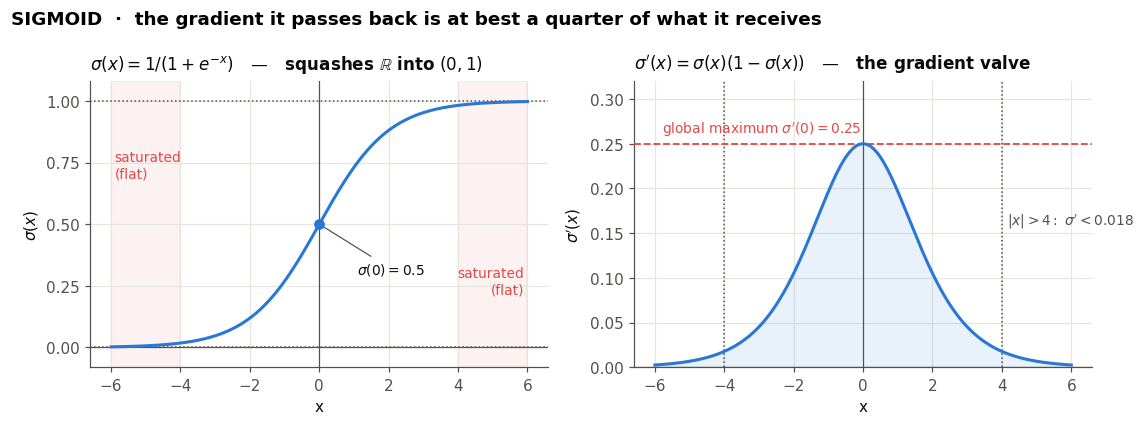

max sigma'      = 0.2500 at x = +0.00
  sigma'( 0) = 0.250000
  sigma'( 1) = 0.196612
  sigma'( 2) = 0.104994
  sigma'( 4) = 0.017663
  sigma'( 6) = 0.002467
  sigma'( 8) = 0.000335


In [4]:
# --- 2.3 Sigmoid and its derivative, with the saturation zones marked ------
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9))

ax[0].plot(X, sigmoid(X), color=C['sigmoid'], zorder=4)
ax[0].axhline(1, color=MUTE, ls=':', lw=1); ax[0].axhline(0, color=MUTE, ls=':', lw=1)
ax[0].fill_between(X, -0.08, 1.08, where=np.abs(X) > 4, color=BAD, alpha=.07, zorder=0)
ax[0].text(-5.9, .80, 'saturated\n(flat)', color=BAD, fontsize=9, va='top')
ax[0].text( 5.9, .22, 'saturated\n(flat)', color=BAD, fontsize=9, ha='right')
ax[0].plot([0], [.5], 'o', ms=6, color=C['sigmoid'], zorder=5)
ax[0].annotate(r'$\sigma(0)=0.5$', (0, .5), (1.1, .30), color=INK, fontsize=9,
               arrowprops=dict(arrowstyle='-', color=MUTE, lw=.8))
ax[0].set_ylim(-.08, 1.08); ax[0].yaxis.set_major_locator(MultipleLocator(.25))
style(ax[0], r'$\sigma(x)=1/(1+e^{-x})$   —   squashes $\mathbb{R}$ into $(0,1)$', ylabel=r'$\sigma(x)$')

ax[1].plot(X, d_sigmoid(X), color=C['sigmoid'], zorder=4)
ax[1].fill_between(X, 0, d_sigmoid(X), color=C['sigmoid'], alpha=.10, zorder=2)
ax[1].axhline(.25, color=BAD, ls='--', lw=1.2, zorder=3)
ax[1].text(-5.8, .262, r"global maximum $\sigma'(0)=0.25$", color=BAD, fontsize=9)
for s in (-4, 4):
    ax[1].axvline(s, color=MUTE, ls=':', lw=1)
ax[1].text(4.15, .16, r"$|x|>4:\ \sigma' < 0.018$", color=MUTE, fontsize=9, ha='left')
ax[1].set_ylim(0, .32)
style(ax[1], r"$\sigma'(x)=\sigma(x)(1-\sigma(x))$   —   the gradient valve", ylabel=r"$\sigma'(x)$")

fig.suptitle('SIGMOID  ·  the gradient it passes back is at best a quarter of what it receives',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

print(f"max sigma'      = {d_sigmoid(X).max():.4f} at x = {X[np.argmax(d_sigmoid(X))]:+.2f}")
for x0 in (0, 1, 2, 4, 6, 8):
    print(f"  sigma'({x0:>2}) = {float(d_sigmoid(x0)):.6f}")

### 2.4 Failure mode 1 — the vanishing gradient

From Lab 03, the gradient reaching layer $\ell$ of an $L$-layer net contains the
product

$$\frac{\partial \mathcal{L}}{\partial \mathbf{h}_\ell}\;\propto\;
\prod_{k=\ell+1}^{L}\sigma'(z_k)\,W_k$$

Every sigmoid contributes a factor $\le 0.25$. Even in the **best possible case**
(every unit sitting exactly at $x=0$), the gradient is attenuated by $4^{-L}$:

| depth $L$ | best-case factor $0.25^{L}$ |
|---|---|
| 5 | $9.8\times10^{-4}$ |
| 10 | $9.5\times10^{-7}$ |
| 20 | $9.1\times10^{-13}$ |
| 40 | $8.3\times10^{-25}$ — below `float32` resolution |

The early layers — the ones that learn the *general* features — receive nothing.
Training stalls at "the last two layers learned something."

> **Reading the ReLU line.** ReLU's local derivative is *exactly* 1 wherever the
> unit is active, so the product along any active path is exactly 1 — a flat line,
> no attenuation at any depth. Roughly half the units are inactive on a given
> input, and He initialisation ($\mathrm{Var}=2/n_{\text{in}}$) exists precisely to
> compensate for that missing half. §6.2 measures the resulting gradient in a real
> 20-layer network, where all of this is accounted for.

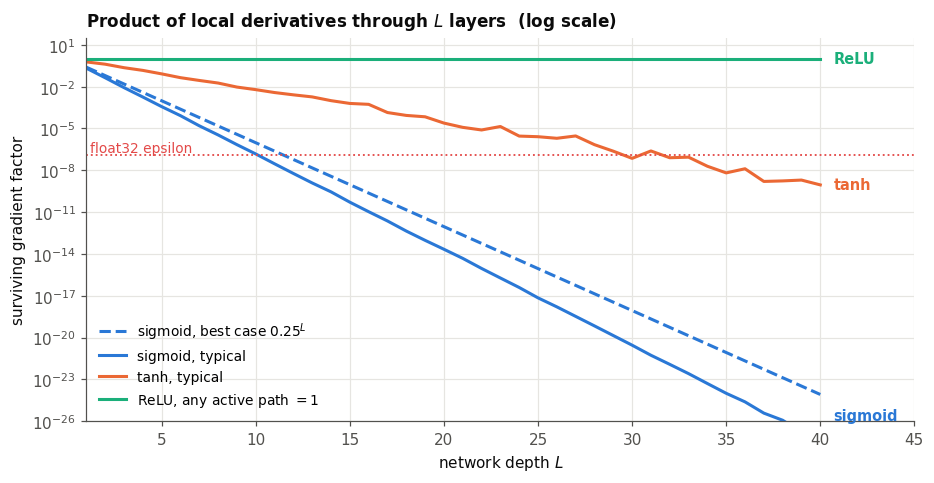

sigmoid @ depth 20 : 2.168e-14
tanh    @ depth 20 : 2.451e-05   (1,130,527,760x larger)
ReLU    @ depth 20 : 1.000e+00       (exactly 1 -- no attenuation at all)


In [5]:
# --- 2.4 How much of the gradient survives L saturating layers? -----------
depths = np.arange(1, 41)
best   = 0.25 ** depths                       # sigmoid, every unit parked at x = 0

rng = np.random.default_rng(7)
def chain_product(dfn, depth, trials=400, scale=1.0):
    # pre-activations ~ N(0, scale^2): a typical trained layer
    z = rng.normal(0, scale, size=(trials, depth))
    return np.exp(np.log(dfn(z) + 1e-300).sum(axis=1)).mean()

sig_real  = np.array([chain_product(d_sigmoid, d) for d in depths])
tanh_real = np.array([chain_product(d_tanh,    d) for d in depths])
relu_path = np.ones_like(depths, dtype=float)   # ReLU: phi' == 1 on every ACTIVE unit

fig, ax = plt.subplots(figsize=(8.6, 4.5))
ax.semilogy(depths, best,      color=C['sigmoid'], ls='--', label=r"sigmoid, best case $0.25^L$")
ax.semilogy(depths, sig_real,  color=C['sigmoid'],           label=r"sigmoid, typical")
ax.semilogy(depths, tanh_real, color=C['tanh'],              label=r"tanh, typical")
ax.semilogy(depths, relu_path, color=C['relu'],              label=r"ReLU, any active path $= 1$")
ax.axhline(1.2e-7, color=BAD, ls=':', lw=1.2)
ax.text(1.2, 2.2e-7, 'float32 epsilon', color=BAD, fontsize=9)
ax.set_ylim(1e-26, 30)
for y, txt, col in [(max(sig_real[-1], 2.5e-26), 'sigmoid', C['sigmoid']),
                    (tanh_real[-1], 'tanh',   C['tanh']),
                    (1.0,           'ReLU',   C['relu'])]:
    ax.annotate(txt, (40.7, y), color=col, fontsize=9.5, fontweight='bold', va='center')
ax.set_xlim(1, 45); ax.legend(loc='lower left', fontsize=9)
style(ax, 'Product of local derivatives through $L$ layers  (log scale)',
      xlabel='network depth $L$', ylabel='surviving gradient factor', zero=False)
fig.tight_layout(); plt.show()

print(f'sigmoid @ depth 20 : {sig_real[19]:.3e}')
print(f'tanh    @ depth 20 : {tanh_real[19]:.3e}   ({tanh_real[19] / sig_real[19]:,.0f}x larger)')
print(f'ReLU    @ depth 20 : 1.000e+00       (exactly 1 -- no attenuation at all)')

### 2.5 Failure mode 2 — not zero-centred

Sigmoid outputs are **always positive**. Those outputs are the next layer's
inputs, and for weight $w_i$ of that layer

$$\frac{\partial \mathcal{L}}{\partial w_i}=\delta \cdot a_i,\qquad a_i=\sigma(\cdot)>0$$

so **every component of the weight gradient carries the sign of $\delta$**. All
weights into a neuron must increase together or decrease together on a given
sample. The optimiser can only move in two of the four quadrants, so it
approaches an off-diagonal optimum by zig-zagging.

Practically this shows up as an **ill-conditioned loss surface**: all-positive
features correlate, the Hessian stretches, and gradient descent bounces down a
narrow valley. Centring the inputs fixes it — which is precisely what `tanh`
does for free.

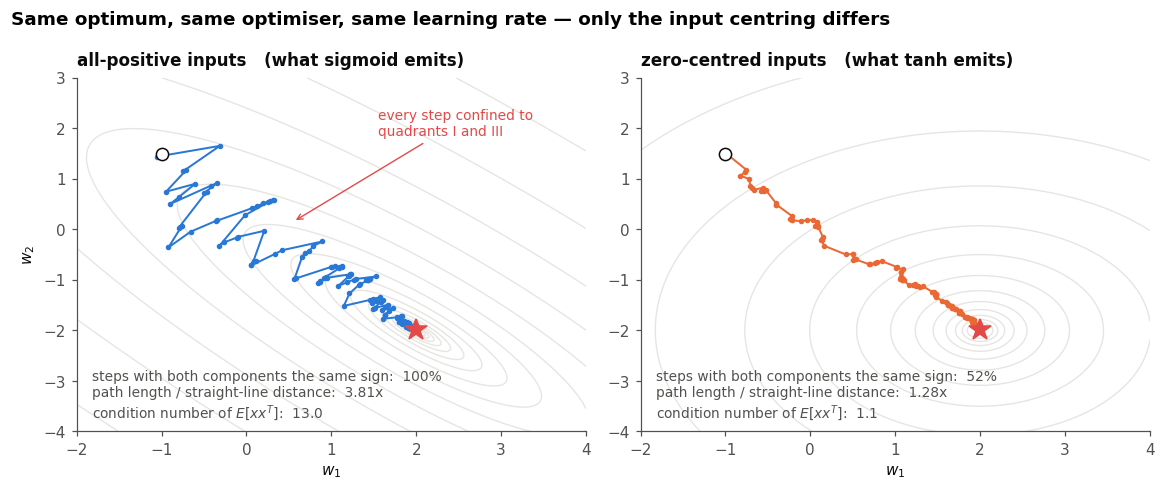

In [6]:
# --- 2.5 The sign-coupling constraint, and the zig-zag it causes ----------
# Linear unit, noiseless targets t = x . w*, so BOTH cases share the same
# optimum w* = (2, -2). Only the input distribution differs.
rng = np.random.default_rng(2)
n, wstar = 600, np.array([2.0, -2.0])
x_pos = rng.uniform(0.2, 1.2, size=(n, 2))      # all-positive  <- sigmoid outputs
x_cen = x_pos - x_pos.mean(0)                   # zero-centred  <- tanh outputs

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.5))
for ax, (title, Xf, col) in zip(axes, [
        ('all-positive inputs   (what sigmoid emits)', x_pos, C['sigmoid']),
        ('zero-centred inputs   (what tanh emits)',    x_cen, C['tanh'])]):
    t, w, path = Xf @ wstar, np.array([-1.0, 1.5]), []
    for i in range(160):                        # SGD, one sample per step
        k = i % n
        g = ((Xf[k] @ w) - t[k]) * Xf[k]        # dL/dw = delta * x   <-- the point
        w = w - 0.35 * g
        path.append(w.copy())
    path = np.array([[-1.0, 1.5]] + list(path))

    S = Xf.T @ Xf / n                           # loss = (w-w*)' S (w-w*) / 2
    g1, g2 = np.meshgrid(np.linspace(-2, 4, 200), np.linspace(-4, 3, 200))
    d1, d2 = g1 - wstar[0], g2 - wstar[1]
    Z = .5 * (S[0, 0] * d1**2 + 2 * S[0, 1] * d1 * d2 + S[1, 1] * d2**2)
    ax.contour(g1, g2, Z, levels=np.logspace(-3, 1.2, 16), colors=[GRID], linewidths=.9, zorder=0)
    ax.plot(path[:, 0], path[:, 1], color=col, lw=1.3, marker='o', ms=2.6, zorder=3)
    ax.plot(*path[0], 'o', ms=8, mfc='white', mec=INK, zorder=4)
    ax.plot(*wstar, '*', ms=15, color=BAD, zorder=4)

    st     = np.diff(path, axis=0)
    same   = (np.sign(st[:, 0]) == np.sign(st[:, 1])).mean()
    detour = np.linalg.norm(st, axis=1).sum() / np.linalg.norm(path[-1] - path[0])
    ax.set_title(title, loc='left', pad=8); ax.grid(False); ax.set_xlabel('$w_1$')
    ax.text(.03, .04, f'steps with both components the same sign:  {same:.0%}\n'
                      f'path length / straight-line distance:  {detour:.2f}x\n'
                      f'condition number of $E[xx^T]$:  {np.linalg.cond(S):.1f}',
            transform=ax.transAxes, fontsize=9, color=MUTE)
axes[0].set_ylabel('$w_2$')
axes[0].annotate('every step confined to\nquadrants I and III', (0.55, 0.15), (1.55, 1.85),
                 color=BAD, fontsize=9,
                 arrowprops=dict(arrowstyle='->', color=BAD, lw=.9))
fig.suptitle('Same optimum, same optimiser, same learning rate — only the input centring differs',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

### 2.6 Sigmoid — datasheet

**Good**

- Output lies in $(0,1)$, so it **reads as a probability**. Whether it is *calibrated* (does 0.8 come true 80% of
  the time?) depends on the data and the training, not on the function; check it with a reliability plot.
- Smooth and differentiable everywhere; well-behaved second derivative.
- Cheap backward pass: $\sigma' = a(1-a)$ from the cached forward value.
- Bounded output → no activation explosion.

**Bad**

- $\sigma' \le 0.25$ ⇒ **vanishing gradients**; unusable as a deep hidden activation.
- **Saturates**: a unit driven past $|x|\approx 4$ stops learning almost entirely.
- **Not zero-centred** ⇒ ill-conditioned updates (§2.5).
- `exp()` in the forward pass is costlier than a comparison.

**Use it**

- **Output layer, binary classification** — paired with binary cross-entropy.
- **Output layer, multi-label** classification (each label independent — §5.5).
- **Gates** inside LSTM / GRU / attention, where a value in $(0,1)$ *is* the
  semantics ("how much to let through"). Here saturation is a feature.
- Any head that must emit a bounded score, e.g. an attention or confidence mask.

**Do not use it**

- As the hidden activation of a deep feed-forward or convolutional network. Since
  ~2011 there is no reason to; use ReLU or a variant.
- On a hidden layer feeding another sigmoid layer — you compound both flaws.
- Anywhere a multi-class **exclusive** decision is needed (that's softmax, §5).

> **Exam-trap.** "Sigmoid is used for binary classification" is only true of the
> **output** layer. Sigmoid in the *hidden* layers is what made pre-2010 deep
> networks untrainable.

---
## 3 · Tanh (hyperbolic tangent)

$$\boxed{\;\tanh(x)=\frac{e^{x}-e^{-x}}{e^{x}+e^{-x}}=\frac{1-e^{-2x}}{1+e^{-2x}}\;}
\qquad \tanh:\mathbb{R}\to(-1,1)$$

### 3.1 Tanh *is* a rescaled sigmoid

$$\tanh(x)=2\,\sigma(2x)-1$$

Same S-shape, but **stretched vertically to $(-1,1)$ and horizontally compressed
by 2**. Two consequences follow immediately:

- **It is zero-centred.** $\tanh(0)=0$, and the output mean over symmetric input
  is 0. Failure mode 2 of §2.5 disappears.
- **Its derivative is 4× larger at the origin.** From the chain rule on the
  identity above, $\tanh'(x) = 4\sigma'(2x)$, so $\tanh'(0)=4(0.25)=1$.

$$\boxed{\;\tanh'(x)=1-\tanh^{2}(x)\;}\qquad \max \tanh' = 1 \text{ at } x=0$$

A derivative of exactly 1 at the origin means a tanh unit operating near zero is
**gradient-transparent** — it passes the signal back untouched. That is why tanh
was the respectable choice for RNNs long after sigmoid was abandoned for hidden
layers.

### 3.2 But it still saturates

$\tanh'(x) \to 0$ just as fast for large $|x|$: at $x=3$, $\tanh' = 0.0099$. Tanh
**delays** the vanishing-gradient problem, it does not solve it — see the §2.4
plot, where the tanh curve falls off a cliff too, just a few layers later.

In [7]:
# --- 3.1 Verify tanh(x) = 2*sigmoid(2x) - 1 and tanh'(x) = 4*sigmoid'(2x) --
lhs, rhs = tanh(X), 2 * sigmoid(2 * X) - 1
print('identity  tanh(x) == 2*sigma(2x) - 1   :', np.allclose(lhs, rhs),
      f'  max|diff| = {np.abs(lhs - rhs).max():.2e}')
lhs2, rhs2 = d_tanh(X), 4 * d_sigmoid(2 * X)
print("identity  tanh'(x) == 4*sigma'(2x)     :", np.allclose(lhs2, rhs2),
      f'  max|diff| = {np.abs(lhs2 - rhs2).max():.2e}')
print()
print(f"max tanh'  = {d_tanh(X).max():.4f}   (vs sigmoid 0.25 -> 4x the gradient)")
for x0 in (0, 1, 2, 3, 4, 6):
    print(f"  tanh'({x0}) = {float(d_tanh(x0)):.6f}   sigma'({x0}) = {float(d_sigmoid(x0)):.6f}")

identity  tanh(x) == 2*sigma(2x) - 1   : True   max|diff| = 3.33e-16
identity  tanh'(x) == 4*sigma'(2x)     : True   max|diff| = 7.18e-16

max tanh'  = 1.0000   (vs sigmoid 0.25 -> 4x the gradient)
  tanh'(0) = 1.000000   sigma'(0) = 0.250000
  tanh'(1) = 0.419974   sigma'(1) = 0.196612
  tanh'(2) = 0.070651   sigma'(2) = 0.104994
  tanh'(3) = 0.009866   sigma'(3) = 0.045177
  tanh'(4) = 0.001341   sigma'(4) = 0.017663
  tanh'(6) = 0.000025   sigma'(6) = 0.002467


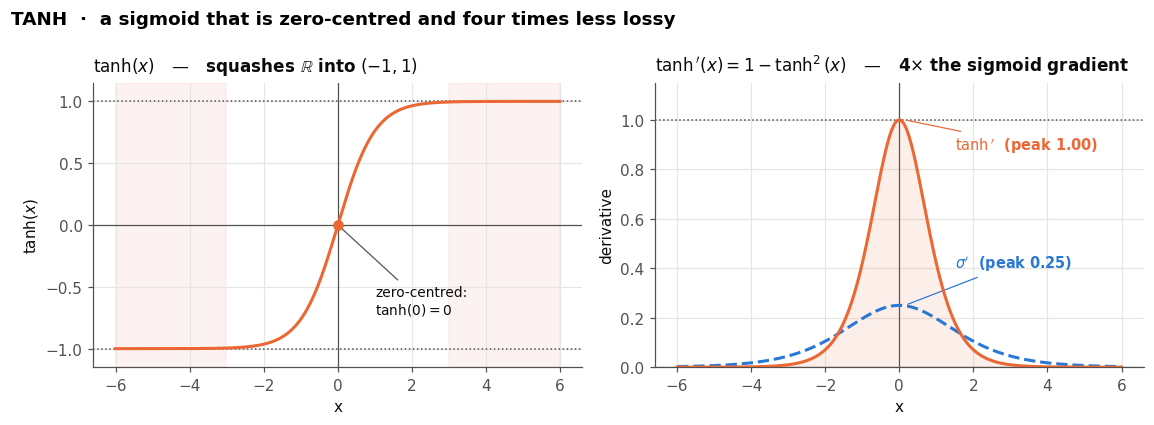

In [8]:
# --- 3.2 Tanh and its derivative ------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9))

ax[0].plot(X, tanh(X), color=C['tanh'], zorder=4)
for h in (-1, 1):
    ax[0].axhline(h, color=MUTE, ls=':', lw=1)
ax[0].fill_between(X, -1.15, 1.15, where=np.abs(X) > 3, color=BAD, alpha=.07, zorder=0)
ax[0].plot([0], [0], 'o', ms=6, color=C['tanh'], zorder=5)
ax[0].annotate('zero-centred:\n$\\tanh(0)=0$', (0, 0), (1.0, -0.72), color=INK, fontsize=9,
               arrowprops=dict(arrowstyle='-', color=MUTE, lw=.8))
ax[0].set_ylim(-1.15, 1.15)
style(ax[0], r'$\tanh(x)$   —   squashes $\mathbb{R}$ into $(-1,1)$', ylabel=r'$\tanh(x)$')

ax[1].plot(X, d_tanh(X), color=C['tanh'], zorder=4)
ax[1].fill_between(X, 0, d_tanh(X), color=C['tanh'], alpha=.10, zorder=2)
ax[1].plot(X, d_sigmoid(X), color=C['sigmoid'], ls='--', zorder=3)
ax[1].axhline(1, color=MUTE, ls=':', lw=1)
ax[1].annotate("$\\tanh'$  (peak 1.00)", (0.15, 1.0), (1.5, .88), color=C['tanh'],
               fontsize=9.5, fontweight='bold',
               arrowprops=dict(arrowstyle='-', color=C['tanh'], lw=.8))
ax[1].annotate("$\\sigma'$  (peak 0.25)", (0.15, .25), (1.5, .40), color=C['sigmoid'],
               fontsize=9.5, fontweight='bold',
               arrowprops=dict(arrowstyle='-', color=C['sigmoid'], lw=.8))
ax[1].set_ylim(0, 1.15)
style(ax[1], r"$\tanh'(x)=1-\tanh^2(x)$   —   4$\times$ the sigmoid gradient", ylabel='derivative')

fig.suptitle('TANH  ·  a sigmoid that is zero-centred and four times less lossy',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

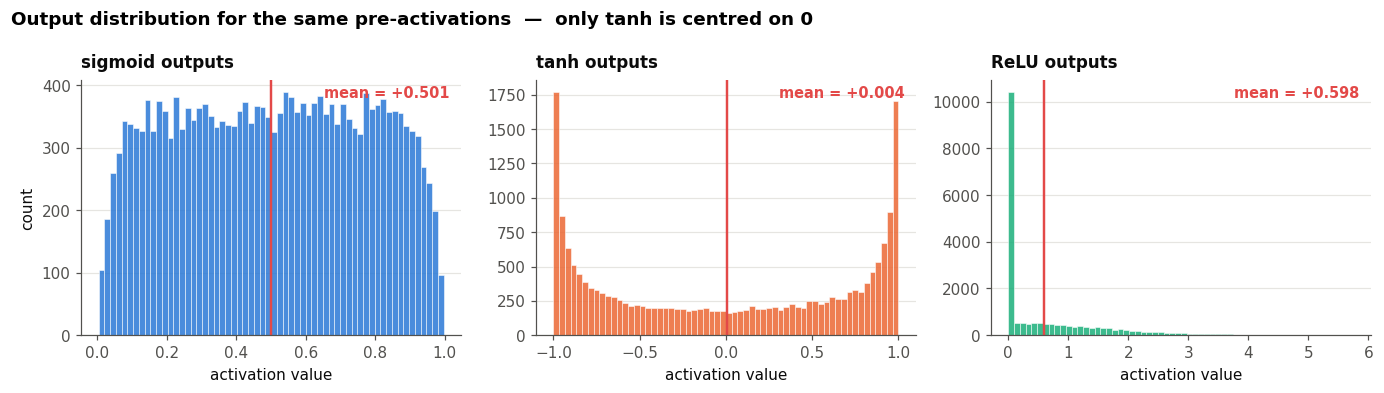

In [9]:
# --- 3.3 Side-by-side: what "zero-centred" does to a layer's outputs -------
rng = np.random.default_rng(11)
z = rng.normal(0, 1.5, size=20000)             # typical pre-activations

fig, ax = plt.subplots(1, 3, figsize=(12.6, 3.6))
for a, (fn, key, name) in zip(ax, [(sigmoid, 'sigmoid', 'sigmoid'),
                                   (tanh, 'tanh', 'tanh'),
                                   (relu, 'relu', 'ReLU')]):
    out = fn(z)
    a.hist(out, bins=60, color=C[key], alpha=.85, edgecolor='white', linewidth=.4)
    a.axvline(out.mean(), color=BAD, lw=1.6)
    a.text(.97, .93, f'mean = {out.mean():+.3f}', transform=a.transAxes, ha='right',
           color=BAD, fontsize=9.5, fontweight='bold')
    a.set_title(f'{name} outputs', loc='left', pad=8)
    a.set_xlabel('activation value'); a.grid(axis='x', visible=False)
ax[0].set_ylabel('count')
fig.suptitle('Output distribution for the same pre-activations  —  only tanh is centred on 0',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

### 3.4 Tanh — datasheet

**Good**

- **Zero-centred** → healthier, better-conditioned gradients than sigmoid.
- $\tanh'(0)=1$ → gradient passes untouched near the origin; **4× sigmoid**.
- Bounded in $(-1,1)$ → activations cannot blow up; valuable in recurrent nets
  where the same weights are applied hundreds of times.
- Smooth, differentiable everywhere; symmetric ($\tanh(-x)=-\tanh(x)$).

**Bad**

- **Still saturates.** Vanishing gradients arrive at depth ~10–15 instead of ~5.
- Two `exp()` per unit — the most expensive of the four in the forward pass.
- No sparsity: every unit is always active, so no free regularisation or speed-up.

**Use it**

- **Recurrent cells** (LSTM/GRU candidate state, vanilla RNN hidden state) — the
  bounded output is exactly what keeps a recurrent loop stable.
- **Hidden layers of small/shallow networks** (< ~8 layers) where smoothness helps.
- **Regression outputs bounded to $[-1,1]$** — normalised audio samples, steering
  angle, a normalised coordinate, the output head of a DDPG-style policy.
- Anywhere you need a smooth, bounded, sign-preserving squash.

**Do not use it**

- Deep plain feed-forward / CNN stacks — ReLU trains faster and deeper.
- Very wide layers where forward-pass cost matters.
- As a probability output — the range is $(-1,1)$, which is not a probability.

> **Rule of thumb.** If your instinct says "sigmoid in a hidden layer",
> tanh is strictly better. If your instinct says "tanh in a deep CNN", ReLU is
> strictly better.

---
## 4 · ReLU (Rectified Linear Unit)

$$\boxed{\;\mathrm{ReLU}(x)=\max(0,x)\;}\qquad \mathrm{ReLU}:\mathbb{R}\to[0,\infty)$$

$$\mathrm{ReLU}'(x)=\begin{cases}1 & x>0\\ 0 & x<0\\ \text{undefined} & x=0\end{cases}$$

### 4.1 Why something this crude works so well

Three properties, and they are all consequences of the *same* fact — the positive
half is the **identity function**:

1. **No saturation on the positive side.** $\mathrm{ReLU}'=1$ for all $x>0$, so the
   chain-rule product $\prod \phi'$ is $1$ along every active path. Depth 50 is as
   gradient-friendly as depth 5. This single property is what made deep CNNs
   trainable (Krizhevsky et al., 2012).
2. **Sparsity.** Roughly half the units output exactly 0 at initialisation. Zeros
   cost nothing to store, kill their downstream contributions, and act as a mild,
   data-dependent regulariser.
3. **Speed.** A comparison and a select. No `exp`, no division. On the backward
   pass, the gradient is a mask — a memory read.

### 4.2 The $x=0$ problem is not a problem

ReLU is not differentiable at the origin. In practice: the probability of a
pre-activation being *exactly* 0.0 in floating point is negligible, and every
framework simply defines $\mathrm{ReLU}'(0)$ by convention (TensorFlow and PyTorch
both use **0**). Formally, ReLU has a *subgradient* on $[0,1]$ at the origin and
subgradient descent is well-founded.

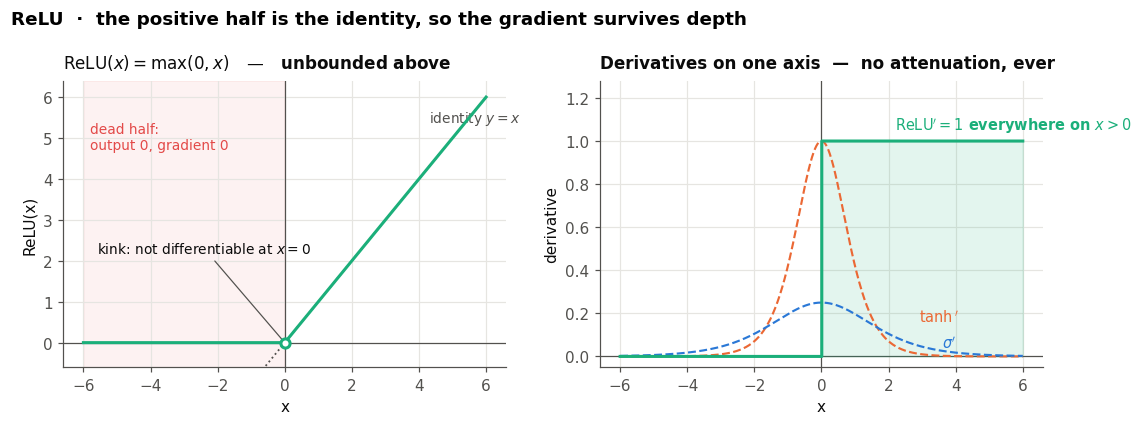

In [10]:
# --- 4.2 ReLU and its derivative ------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9))

ax[0].plot(X, relu(X), color=C['relu'], zorder=4)
ax[0].plot(X, X, color=MUTE, ls=':', lw=1.2, zorder=2)
ax[0].text(4.3, 5.4, 'identity $y=x$', color=MUTE, fontsize=9)
ax[0].fill_between(X, -0.6, 6.4, where=X < 0, color=BAD, alpha=.07, zorder=0)
ax[0].text(-5.8, 5.4, 'dead half:\noutput 0, gradient 0', color=BAD, fontsize=9, va='top')
ax[0].plot([0], [0], 'o', ms=6, mfc='white', mec=C['relu'], mew=2, zorder=5)
ax[0].annotate('kink: not differentiable at $x=0$', (0, 0), (-5.6, 2.2), color=INK, fontsize=9,
               arrowprops=dict(arrowstyle='-', color=MUTE, lw=.8))
ax[0].set_ylim(-.6, 6.4)
style(ax[0], r'$\mathrm{ReLU}(x)=\max(0,x)$   —   unbounded above', ylabel='ReLU(x)')

ax[1].step(X, d_relu(X), where='post', color=C['relu'], zorder=4)
ax[1].fill_between(X, 0, d_relu(X), step='post', color=C['relu'], alpha=.12, zorder=2)
ax[1].plot(X, d_tanh(X), color=C['tanh'], ls='--', lw=1.4, zorder=3)
ax[1].plot(X, d_sigmoid(X), color=C['sigmoid'], ls='--', lw=1.4, zorder=3)
ax[1].text(2.2, 1.05, "$\\mathrm{ReLU}'=1$ everywhere on $x>0$", color=C['relu'],
           fontsize=9.5, fontweight='bold')
ax[1].text(2.9, .16, "$\\tanh'$", color=C['tanh'], fontsize=9.5, fontweight='bold')
ax[1].text(3.6, .04, "$\\sigma'$", color=C['sigmoid'], fontsize=9.5, fontweight='bold')
ax[1].set_ylim(-.05, 1.28)
style(ax[1], "Derivatives on one axis  —  no attenuation, ever", ylabel='derivative')

fig.suptitle('ReLU  ·  the positive half is the identity, so the gradient survives depth',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

### 4.3 Failure mode — the **dying ReLU**

A ReLU unit whose pre-activation is negative for **every** input in the dataset
outputs 0 always, so its gradient is 0 always, so its weights never change again.
The unit is permanently dead — it has removed itself from the network.

The usual cause is a **large gradient step that drives the bias strongly
negative**: too high a learning rate, or an unlucky initialisation. Once dead, it
cannot recover, because recovery would require a gradient it can no longer receive.

Run the next cell: the same network, the same data, only the learning rate
changes. Watch the dead fraction climb first (the network copes while it still has enough live units), and then
the accuracy collapse.

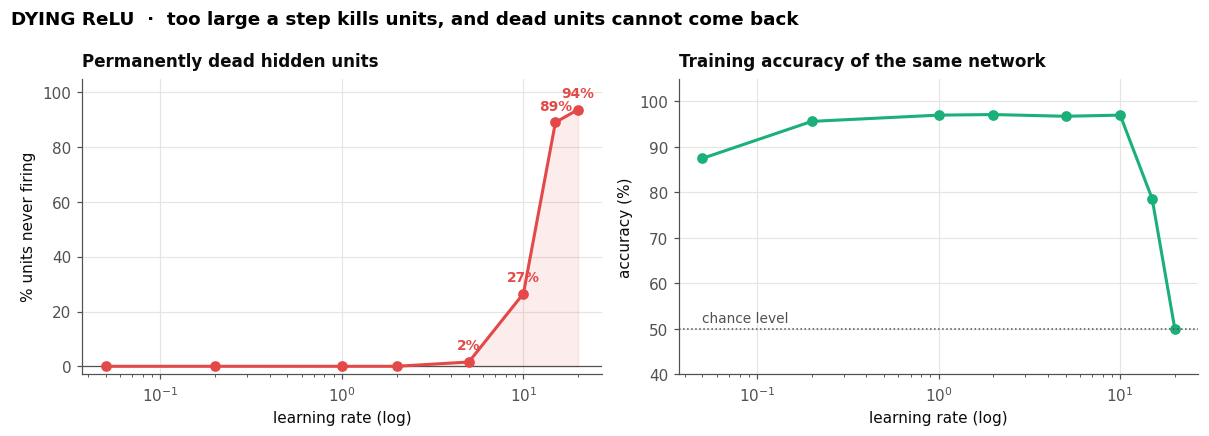

 lr      dead units    accuracy
   0.05       0.0%       87.5%
   0.20       0.0%       95.6%
   1.00       0.0%       97.0%
   2.00       0.0%       97.1%
   5.00       1.6%       96.8%
  10.00      26.6%       97.0%
  15.00      89.1%       78.6%
  20.00      93.8%       50.0%


In [11]:
# --- 4.3 Dying ReLU: dead-unit fraction as a function of learning rate -----
from sklearn.datasets import make_moons
Xd, yd = make_moons(n_samples=800, noise=0.20, random_state=5)
Xd = (Xd - Xd.mean(0)) / Xd.std(0); yd = yd.reshape(-1, 1)

def train_relu_mlp(lr, hidden=64, steps=400, seed=0):
    rng = np.random.default_rng(seed)
    W1 = rng.normal(0, np.sqrt(2 / 2), size=(2, hidden))   # He init
    b1 = np.zeros(hidden)
    W2 = rng.normal(0, np.sqrt(2 / hidden), size=(hidden, 1)); b2 = np.zeros(1)
    for _ in range(steps):
        z1 = Xd @ W1 + b1; a1 = relu(z1)
        p  = sigmoid(a1 @ W2 + b2)
        d2 = (p - yd) / len(Xd)
        gW2, gb2 = a1.T @ d2, d2.sum(0)
        d1 = (d2 @ W2.T) * (z1 > 0)
        gW1, gb1 = Xd.T @ d1, d1.sum(0)
        W1 -= lr * gW1; b1 -= lr * gb1; W2 -= lr * gW2; b2 -= lr * gb2
    z1 = Xd @ W1 + b1
    dead = (z1 <= 0).all(axis=0).mean()                    # never fires on ANY sample
    acc  = ((sigmoid(relu(z1) @ W2 + b2) > .5) == yd).mean()
    return dead, acc, relu(z1)

lrs   = np.array([0.05, 0.2, 1.0, 2.0, 5.0, 10.0, 15.0, 20.0])
res   = [train_relu_mlp(lr) for lr in lrs]
deadf = np.array([r[0] for r in res]); accs = np.array([r[1] for r in res])

fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.0))
ax[0].semilogx(lrs, deadf * 100, color=BAD, marker='o', ms=6)
ax[0].fill_between(lrs, 0, deadf * 100, color=BAD, alpha=.10)
for lr, d in zip(lrs, deadf * 100):
    if d > 1: ax[0].annotate(f'{d:.0f}%', (lr, d), (0, 8), textcoords='offset points',
                             ha='center', fontsize=9, color=BAD, fontweight='bold')
ax[0].set_ylim(-3, 105)
style(ax[0], 'Permanently dead hidden units', xlabel='learning rate (log)', ylabel='% units never firing')

ax[1].semilogx(lrs, accs * 100, color=C['relu'], marker='o', ms=6)
ax[1].axhline(50, color=MUTE, ls=':', lw=1)
ax[1].text(lrs[0], 51.5, 'chance level', color=MUTE, fontsize=9)
ax[1].set_ylim(40, 105)
style(ax[1], 'Training accuracy of the same network', xlabel='learning rate (log)', ylabel='accuracy (%)')
fig.suptitle('DYING ReLU  ·  too large a step kills units, and dead units cannot come back',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

print(' lr      dead units    accuracy')
for lr, d, a in zip(lrs, deadf, accs):
    print(f'{lr:7.2f}   {d:8.1%}   {a:9.1%}')

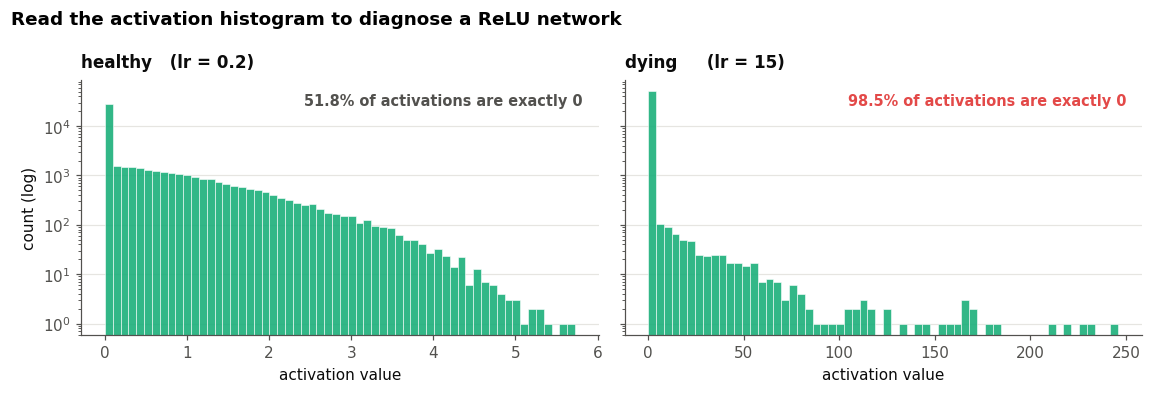

Diagnostic rule of thumb: 40-70% zeros is healthy sparsity. >90% means units are dying.


In [12]:
# --- 4.4 The healthy signature: a sparse, one-sided activation histogram ---
_, _, a_good = train_relu_mlp(0.2)
_, _, a_bad  = train_relu_mlp(15.0)

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=True)
for a, act, title in [(ax[0], a_good, 'healthy   (lr = 0.2)'),
                      (ax[1], a_bad,  'dying     (lr = 15)')]:
    a.hist(act.ravel(), bins=60, color=C['relu'], alpha=.9, edgecolor='white', linewidth=.4)
    z = (act == 0).mean()
    a.text(.97, .90, f'{z:.1%} of activations are exactly 0',
           transform=a.transAxes, ha='right', fontsize=9.5,
           color=BAD if z > .8 else MUTE, fontweight='bold')
    a.set_title(title, loc='left', pad=8); a.set_xlabel('activation value')
    a.set_yscale('log'); a.grid(axis='x', visible=False)
ax[0].set_ylabel('count (log)')
fig.suptitle('Read the activation histogram to diagnose a ReLU network',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()
print('Diagnostic rule of thumb: 40-70% zeros is healthy sparsity. >90% means units are dying.')

### 4.5 The ReLU family — fixing the dead half

Every variant does the same thing: **give the negative side a non-zero slope**, so
a unit pushed negative can still receive gradient and climb back.

| Variant | Definition | Negative-side gradient | Note |
|---|---|---|---|
| **Leaky ReLU** | $\max(\alpha x, x)$, $\alpha = 0.01$ | $\alpha$ | one extra multiply; no dead units, ever |
| **PReLU** | same, $\alpha$ **learned** | learned | +1 parameter per channel |
| **ELU** | $x$ if $x>0$ else $\alpha(e^{x}-1)$ | $\alpha e^{x}$ | saturates negatively → noise-robust; pushes mean toward 0 |
| **GELU** | $x\,\Phi(x)$ | smooth | the transformer default (BERT, GPT) |
| **SiLU / Swish** | $x\,\sigma(x)$ | smooth, non-monotonic | EfficientNet default; ~GELU at lower cost |

GELU and SiLU are **smooth and non-monotonic** — they dip slightly below zero
around $x\approx-1$. That small negative lobe is not a bug: it lets the unit
express "weakly opposed" instead of only "off", and it makes the loss surface
differentiable everywhere.

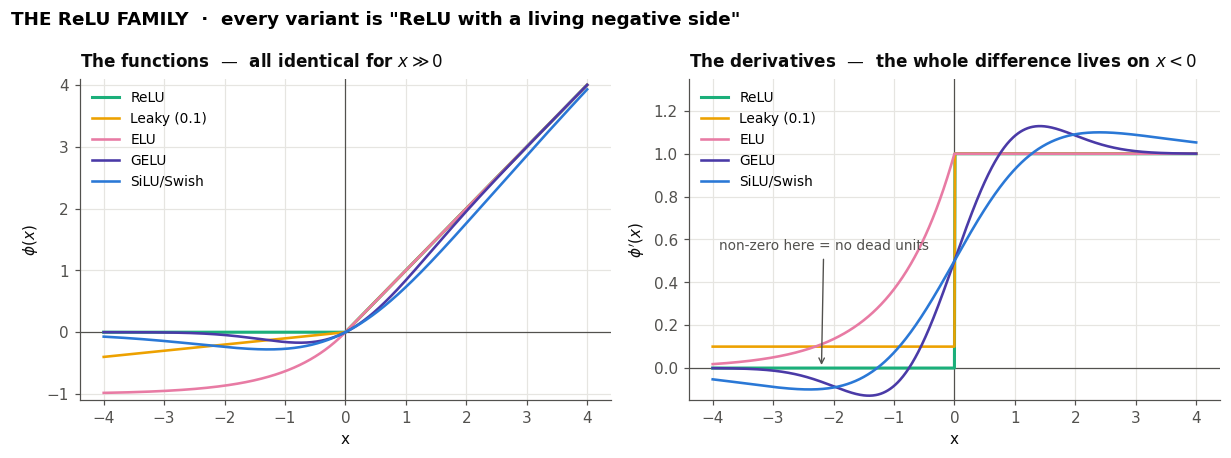

     x         ReLU  Leaky (0.1)          ELU         GELU   SiLU/Swish
  -3.0       0.0000      -0.3000      -0.9502      -0.0040      -0.1423
  -1.0       0.0000      -0.1000      -0.6321      -0.1587      -0.2689
  -0.5       0.0000      -0.0500      -0.3935      -0.1543      -0.1888
   0.0       0.0000       0.0000       0.0000       0.0000       0.0000
   0.5       0.5000       0.5000       0.5000       0.3457       0.3112
   2.0       2.0000       2.0000       2.0000       1.9545       1.7616


In [13]:
# --- 4.5 The ReLU family, functions and derivatives ------------------------
from scipy.special import erf
SQ2, SQ2PI = np.sqrt(2.0), np.sqrt(2.0 * np.pi)

def leaky(x, a=0.01):  return np.where(x > 0, x, a * x)
def d_leaky(x, a=0.01): return np.where(x > 0, 1.0, a)
def elu(x, a=1.0):     return np.where(x > 0, x, a * (np.exp(np.minimum(x, 0)) - 1))
def d_elu(x, a=1.0):   return np.where(x > 0, 1.0, a * np.exp(np.minimum(x, 0)))
def gelu(x):           return 0.5 * x * (1 + erf(x / SQ2))
def d_gelu(x):         return 0.5 * (1 + erf(x / SQ2)) + x * np.exp(-x**2 / 2) / SQ2PI
def silu(x):           return x * sigmoid(x)
def d_silu(x):         s = sigmoid(x); return s * (1 + x * (1 - s))

FAM = [('ReLU',       relu,   d_relu,   C['relu']),
       ('Leaky (0.1)', lambda v: leaky(v, .1), lambda v: d_leaky(v, .1), '#eda100'),
       ('ELU',        elu,    d_elu,    '#e87ba4'),
       ('GELU',       gelu,   d_gelu,   C['softmax']),
       ('SiLU/Swish', silu,   d_silu,   C['sigmoid'])]

Xf = np.linspace(-4, 4, 801)
fig, ax = plt.subplots(1, 2, figsize=(11.2, 4.2))
for name, f, df, col in FAM:
    ax[0].plot(Xf, f(Xf), color=col, label=name, lw=2 if name == 'ReLU' else 1.7)
    ax[1].plot(Xf, df(Xf), color=col, label=name, lw=2 if name == 'ReLU' else 1.7)
ax[0].set_ylim(-1.1, 4.1); ax[1].set_ylim(-.15, 1.35)
ax[0].legend(loc='upper left', fontsize=9)
ax[1].legend(loc='upper left', fontsize=9)
style(ax[0], 'The functions  —  all identical for $x \\gg 0$', ylabel=r'$\phi(x)$')
style(ax[1], "The derivatives  —  the whole difference lives on $x<0$", ylabel=r"$\phi'(x)$")
ax[1].annotate('non-zero here = no dead units', (-2.2, .0), (-3.9, .55), color=MUTE, fontsize=9,
               arrowprops=dict(arrowstyle='->', color=MUTE, lw=.9))
fig.suptitle('THE ReLU FAMILY  ·  every variant is "ReLU with a living negative side"',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

print(f'{"x":>6}' + ''.join(f'{n:>13}' for n, *_ in FAM))
for x0 in (-3.0, -1.0, -0.5, 0.0, 0.5, 2.0):
    print(f'{x0:>6.1f}' + ''.join(f'{float(f(np.array(x0))):>13.4f}' for _, f, *_ in FAM))

### 4.6 ReLU — datasheet

**Good**

- **No vanishing gradient on the active path** — $\phi'=1$. The reason deep nets train.
- **Fastest** of the four: one comparison forward, one mask backward.
- **Sparse** activations (~50% zeros) → cheaper downstream, mild regularisation.
- Empirically converges several times faster than tanh on the same architecture.
- Scale-equivariant: $\mathrm{ReLU}(cx)=c\,\mathrm{ReLU}(x)$ for $c>0$.

**Bad**

- **Dying ReLU** — permanent unit death from a large step (§4.3).
- **Not zero-centred** — output mean $>0$ (same conditioning issue as sigmoid,
  which is why BatchNorm/LayerNorm pairs so well with it).
- **Unbounded above** → activations can explode; needs sane initialisation
  (He/Kaiming) and often normalisation.
- Non-differentiable at 0 (harmless in practice).

**Use it**

- **Default hidden activation** for CNNs and plain MLPs. Start here, always.
- Any deep stack where training speed matters.
- With **He/Kaiming initialisation** — $\mathcal{N}(0, 2/n_{\text{in}})$ — which is
  derived specifically for ReLU's half-killed variance.

**Do not use it**

- On the **output layer**. It cannot emit a negative value or a probability, and even for a non-negative
  regression (counts, intensities, durations) **softplus** is safer: a ReLU output that goes negative for an
  example passes back *zero* gradient for it, so the prediction can stick at 0.
- In **recurrent** loops without care — unbounded output compounds over timesteps
  and explodes.
- When you observe >90% dead units — switch to **Leaky ReLU / ELU / GELU** or
  lower the learning rate.
- Where a smooth second derivative is required (some physics-informed nets).

> **Practical default (2026).** CNN / MLP → **ReLU**. Transformer → **GELU**.
> Efficiency-tuned vision → **SiLU**. Diagnosed dying units → **Leaky ReLU**.

---
## 5 · Softmax

The odd one out. Sigmoid, tanh and ReLU are **scalar** functions applied
element-wise. Softmax is a **vector** function: every output depends on **every**
input.

$$\boxed{\;\mathrm{softmax}(\mathbf{z})_i=\frac{e^{z_i}}{\sum_{j=1}^{K}e^{z_j}}\;}
\qquad \mathrm{softmax}:\mathbb{R}^{K}\to \Delta^{K-1}$$

The output lives on the **probability simplex**: every $p_i\in(0,1)$ and
$\sum_i p_i = 1$ **by construction**. That coupling is the point — it makes the
classes *compete*. Raising one logit necessarily lowers every other probability.

### 5.1 Reading the name

It is a soft **arg max**, not a soft max. As the logit gap grows, the
distribution approaches the one-hot vector that `argmax` would return — but
smoothly, and therefore differentiably. `argmax` has zero gradient everywhere and
cannot be trained through; softmax can.

### 5.2 The Jacobian

Because output $i$ depends on input $j$, the derivative is a **$K\times K$ matrix**:

$$\frac{\partial p_i}{\partial z_j}=p_i\left(\delta_{ij}-p_j\right)
=\begin{cases} p_i(1-p_i) & i=j \quad(\text{positive — echoes } \sigma')\\
 -p_i p_j & i\neq j \quad(\text{negative — competition})\end{cases}$$

Note the diagonal is exactly the sigmoid derivative form. The **off-diagonal is
negative**: push class $i$ up and class $j$ *must* come down.

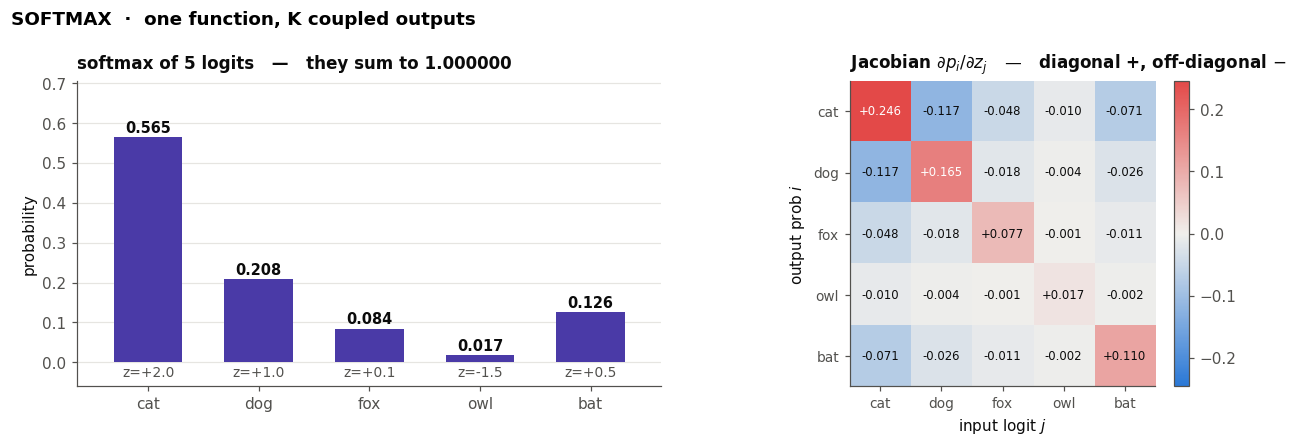

rows of J sum to zero (probabilities must keep summing to 1): [0. 0. 0. 0. 0.]
J is symmetric: True


In [14]:
# --- 5.2 Softmax on a logit vector, and its Jacobian ----------------------
z = np.array([2.0, 1.0, 0.1, -1.5, 0.5])
labels = ['cat', 'dog', 'fox', 'owl', 'bat']
p = softmax(z)

J = np.diag(p) - np.outer(p, p)            # dp_i/dz_j = p_i(delta_ij - p_j)

from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
DIVERGE = LinearSegmentedColormap.from_list('viz', ['#2a78d6', '#f0efec', '#e34948'])

fig, ax = plt.subplots(1, 2, figsize=(11.4, 4.1),
                       gridspec_kw={'width_ratios': [1.25, 1]})

b = ax[0].bar(labels, p, color=C['softmax'], width=.62, zorder=3)
ax[0].bar(labels, np.full(len(z), 0), color='none')
for r, zi, pi in zip(b, z, p):
    ax[0].text(r.get_x() + r.get_width() / 2, pi + .012, f'{pi:.3f}',
               ha='center', fontsize=9.5, color=INK, fontweight='bold')
    ax[0].text(r.get_x() + r.get_width() / 2, -.035, f'z={zi:+.1f}',
               ha='center', fontsize=9, color=MUTE)
ax[0].set_ylim(-.06, max(p) * 1.25); ax[0].grid(axis='x', visible=False)
ax[0].set_title(f'softmax of 5 logits   —   they sum to {p.sum():.6f}', loc='left', pad=8)
ax[0].set_ylabel('probability')

im = ax[1].imshow(J, cmap=DIVERGE, norm=TwoSlopeNorm(vcenter=0, vmin=-J.max(), vmax=J.max()))
ax[1].set_xticks(range(5), labels, fontsize=9); ax[1].set_yticks(range(5), labels, fontsize=9)
for i in range(5):
    for j in range(5):
        ax[1].text(j, i, f'{J[i, j]:+.3f}', ha='center', va='center', fontsize=7.6,
                   color=INK if abs(J[i, j]) < J.max() * .6 else 'white')
ax[1].set_title(r'Jacobian $\partial p_i/\partial z_j$   —   diagonal +, off-diagonal $-$',
                loc='left', pad=8)
ax[1].set_xlabel('input logit $j$'); ax[1].set_ylabel('output prob $i$'); ax[1].grid(False)
fig.colorbar(im, ax=ax[1], fraction=.046, pad=.04)
fig.suptitle('SOFTMAX  ·  one function, K coupled outputs', x=.005, ha='left',
             fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

print('rows of J sum to zero (probabilities must keep summing to 1):', J.sum(axis=1))
print('J is symmetric:', np.allclose(J, J.T))

### 5.3 Numerical stability — the one implementation detail you must know

$$\mathrm{softmax}(\mathbf{z}+c\mathbf{1})=\mathrm{softmax}(\mathbf{z})\quad\text{for any scalar }c$$

because $e^{z_i+c}/\sum_j e^{z_j+c} = e^{c}e^{z_i}/(e^{c}\sum_j e^{z_j})$. Softmax
is **shift-invariant**. Exploit it: subtract the maximum before exponentiating,

```python
z = z - z.max()      # largest exponent becomes exp(0) = 1
```

so the largest term is exactly 1 and nothing overflows. Without it, logits around
$\pm 800$ (entirely ordinary in a large network) produce `inf` or `0/0 = nan`.

This is why you should pass **logits**, not probabilities, to your loss —
`from_logits=True` in Keras, `CrossEntropyLoss` in PyTorch. The framework then
fuses softmax and log into a single numerically stable `log-sum-exp`.

In [15]:
# --- 5.3 Naive vs stable softmax ------------------------------------------
def softmax_naive(z):
    e = np.exp(np.asarray(z, dtype=float))
    return e / e.sum()

for name, zz in [('ordinary logits ', np.array([2.0, 1.0, 0.1])),
                 ('large positive  ', np.array([1000.0, 1001.0, 1002.0])),
                 ('large negative  ', np.array([-1000.0, -1001.0, -1002.0]))]:
    with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
        naive = softmax_naive(zz)
    print(f'{name} z = {zz}')
    print(f'    naive  -> {naive}')
    print(f'    stable -> {softmax(zz)}')
print()
c = 37.5
print('shift-invariance:  softmax(z) == softmax(z + 37.5)?',
      np.allclose(softmax(z), softmax(z + c)))

ordinary logits  z = [2.  1.  0.1]
    naive  -> [0.659  0.2424 0.0986]
    stable -> [0.659  0.2424 0.0986]
large positive   z = [1000. 1001. 1002.]
    naive  -> [nan nan nan]
    stable -> [0.09   0.2447 0.6652]
large negative   z = [-1000. -1001. -1002.]
    naive  -> [nan nan nan]
    stable -> [0.6652 0.2447 0.09  ]

shift-invariance:  softmax(z) == softmax(z + 37.5)? True


### 5.4 Temperature — sharpening and smoothing the distribution

$$\mathrm{softmax}(\mathbf{z}/T)_i = \frac{e^{z_i/T}}{\sum_j e^{z_j/T}}$$

| $T$ | effect | used for |
|---|---|---|
| $T \to 0^{+}$ | one-hot — pure `argmax` | greedy decoding |
| $T = 1$ | the trained distribution | standard inference |
| $T > 1$ | flatter, higher entropy | creative sampling in LLMs; **knowledge distillation** (Hinton et al., 2015) — a soft teacher distribution carries the "dark knowledge" of which wrong classes were plausible |
| $T \to \infty$ | uniform $1/K$ | maximum entropy |

Temperature is *the* sampling knob in every text-generation API you have used.

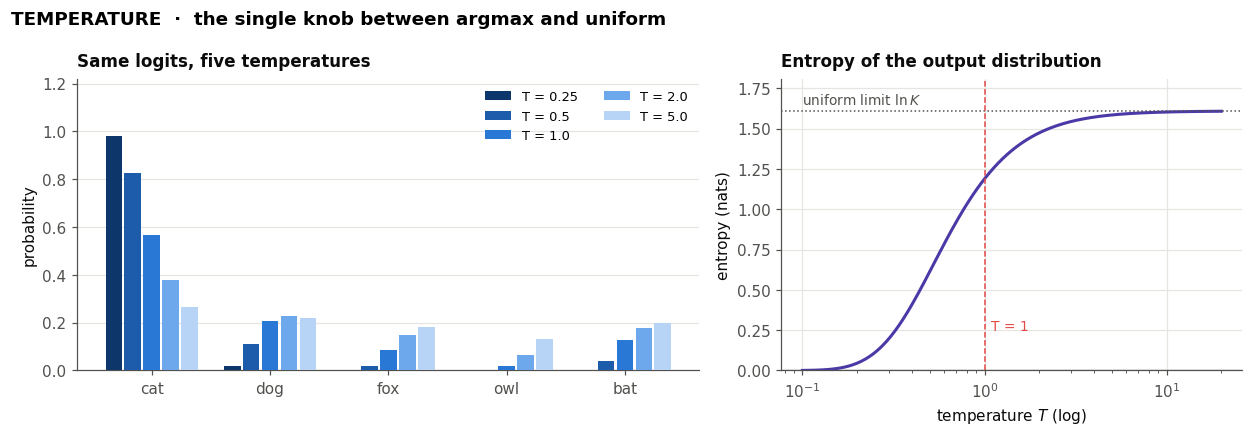

In [16]:
# --- 5.4 Temperature sweep -------------------------------------------------
temps = [0.25, 0.5, 1.0, 2.0, 5.0]
fig, ax = plt.subplots(1, 2, figsize=(11.4, 4.0), gridspec_kw={'width_ratios': [1.35, 1]})

w, xs = .16, np.arange(len(labels))
shades = ['#0d366b', '#1c5cab', '#2a78d6', '#6da7ec', '#b7d3f6']   # one hue, light->dark
for k, (T, col) in enumerate(zip(temps, shades)):
    ax[0].bar(xs + (k - 2) * w, softmax(z / T), width=w * .88, color=col,
              label=f'T = {T}', zorder=3)
ax[0].set_xticks(xs, labels); ax[0].legend(fontsize=8.5, ncol=2, loc='upper right')
ax[0].set_ylim(0, 1.22); ax[0].grid(axis='x', visible=False)
ax[0].set_title('Same logits, five temperatures', loc='left', pad=8)
ax[0].set_ylabel('probability')

Tg = np.logspace(-1, 1.3, 200)
H  = np.array([-(softmax(z / T) * np.log(softmax(z / T) + 1e-12)).sum() for T in Tg])
ax[1].semilogx(Tg, H, color=C['softmax'])
ax[1].axhline(np.log(len(z)), color=MUTE, ls=':', lw=1)
ax[1].text(Tg[0], np.log(len(z)) + .04, r'uniform limit $\ln K$', color=MUTE, fontsize=9)
ax[1].axvline(1, color=BAD, ls='--', lw=1)
ax[1].text(1.08, .25, 'T = 1', color=BAD, fontsize=9)
ax[1].set_ylim(0, np.log(len(z)) + .2)
style(ax[1], 'Entropy of the output distribution', xlabel='temperature $T$ (log)', ylabel='entropy (nats)')
fig.suptitle('TEMPERATURE  ·  the single knob between argmax and uniform',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

### 5.5 Softmax vs sigmoid — the decision that actually matters

|  | **Softmax** | **Sigmoid (per output)** |
|---|---|---|
| Outputs | coupled, $\sum p_i = 1$ | independent, each in $(0,1)$ |
| Question answered | "**which one**?" | "**is each one** true?" |
| Task | multi-class, **mutually exclusive** | **multi-label**, non-exclusive |
| Loss | categorical cross-entropy | binary cross-entropy, summed |
| Example | MNIST digit: a 7 is not also a 3 | photo tags: *beach* **and** *sunset* **and** *people* |

Getting this wrong is the single most common output-layer bug. If an image can
carry two labels at once and you used softmax, you have told the network the
labels compete — it can never assign high probability to both.

### 5.6 Two classes: softmax **is** sigmoid

For $K=2$, softmax reduces exactly to a sigmoid of the logit *difference*:

$$p_1=\frac{e^{z_1}}{e^{z_1}+e^{z_2}}
     =\frac{1}{1+e^{-(z_1-z_2)}}=\sigma(z_1-z_2)$$

So a 2-unit softmax head and a 1-unit sigmoid head are the same model — the
softmax version just carries one redundant parameter set. **For binary
classification, use a single sigmoid.**

  z1       z2      softmax[0]   sigmoid(z1-z2)
 +1.076   +4.532    0.03059898    0.03059898
 -5.359   +5.060    0.00002986    0.00002986
 -0.142   -2.400    0.90533701    0.90533701
 -2.409   -3.248    0.69837662    0.69837662
 -0.671   +2.502    0.04021039    0.04021039
 +1.752   +1.915    0.45942272    0.45942272

identical: True


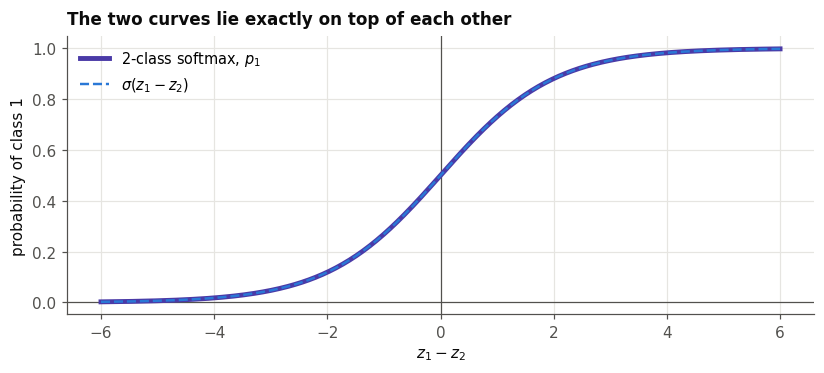

In [17]:
# --- 5.6 Verify softmax(K=2) == sigmoid of the logit difference -----------
rng = np.random.default_rng(21)
Z2 = rng.normal(0, 3, size=(6, 2))
sm = softmax(Z2, axis=1)[:, 0]
sg = sigmoid(Z2[:, 0] - Z2[:, 1])
print('  z1       z2      softmax[0]   sigmoid(z1-z2)')
for (a, b), s1, s2 in zip(Z2, sm, sg):
    print(f'{a:+7.3f}  {b:+7.3f}    {s1:.8f}    {s2:.8f}')
print('\nidentical:', np.allclose(sm, sg))

d = np.linspace(-6, 6, 400)
fig, ax = plt.subplots(figsize=(7.6, 3.5))
ax.plot(d, softmax(np.c_[d, np.zeros_like(d)], axis=1)[:, 0], color=C['softmax'], lw=3.2,
        label='2-class softmax, $p_1$')
ax.plot(d, sigmoid(d), color=C['sigmoid'], lw=1.6, ls='--', label=r'$\sigma(z_1-z_2)$')
ax.legend(fontsize=9.5, loc='upper left')
style(ax, 'The two curves lie exactly on top of each other',
      xlabel='$z_1 - z_2$', ylabel='probability of class 1')
fig.tight_layout(); plt.show()

### 5.7 Why softmax + cross-entropy is the canonical pair

Categorical cross-entropy for a one-hot target $\mathbf{y}$:
$\mathcal{L}=-\sum_i y_i\log p_i$. Compose it with the softmax Jacobian and the
messy $p_i(\delta_{ij}-p_j)$ terms **cancel completely**:

$$\boxed{\;\frac{\partial \mathcal{L}}{\partial z_i}=p_i-y_i\;}$$

The gradient at the logits is just *(prediction − target)*. Three consequences:

1. **No saturation.** The softmax Jacobian could vanish for a confident wrong
   prediction, but the log in cross-entropy is its exact inverse — the two cancel,
   so a confidently wrong output produces a gradient of magnitude ~1, not ~0.
   Pair softmax with **MSE** instead and you reintroduce saturation and slow
   learning.
2. It is trivial to implement and to differentiate by hand (Lab 03).
3. It is why frameworks fuse the two into one op (`softmax_cross_entropy_with_logits`).

Verify it numerically below against a finite-difference gradient.

In [18]:
# --- 5.7 Verify dL/dz = p - y by finite differences ------------------------
def ce_loss(zv, y):
    return -np.sum(y * np.log(softmax(zv) + 1e-300))

z0 = np.array([1.3, -0.7, 2.1, 0.4])
y0 = np.array([0.0,  0.0, 1.0, 0.0])          # true class = index 2

analytic = softmax(z0) - y0
eps, numeric = 1e-6, np.zeros_like(z0)
for i in range(len(z0)):
    zp, zm = z0.copy(), z0.copy()
    zp[i] += eps; zm[i] -= eps
    numeric[i] = (ce_loss(zp, y0) - ce_loss(zm, y0)) / (2 * eps)

print('softmax(z)       :', softmax(z0))
print('analytic  p - y  :', analytic)
print('finite difference:', numeric)
print('max |difference| :', np.abs(analytic - numeric).max())
print('\nGradient survives a confidently WRONG prediction:')
zbad = np.array([12.0, 0.0, 0.0, 0.0])        # screams "class 0", truth is class 2
print('  p       =', softmax(zbad))
print('  dL/dz   =', softmax(zbad) - y0, ' <- magnitude ~1, learning continues')

softmax(z)       : [0.2654 0.0359 0.5907 0.1079]
analytic  p - y  : [ 0.2654  0.0359 -0.4093  0.1079]
finite difference: [ 0.2654  0.0359 -0.4093  0.1079]
max |difference| : 1.1628253915318965e-10

Gradient survives a confidently WRONG prediction:
  p       = [1. 0. 0. 0.]
  dL/dz   = [ 1.  0. -1.  0.]  <- magnitude ~1, learning continues


### 5.8 Softmax — datasheet

**Good**

- Outputs a **valid probability distribution** — normalised, interpretable,
  directly comparable across classes.
- **Differentiable `argmax`** — makes discrete decisions trainable.
- With cross-entropy, gradient is $p-y$: **simple, saturation-free, stable**.
- **Temperature** gives one principled knob for sharpness (sampling, distillation).
- Shift-invariant → a clean stable implementation exists.

**Bad**

- **Assumes exclusivity.** Wrong model for multi-label problems.
- **Cost is $O(K)$ per sample** — a 50,000-word vocabulary means a 50,000-way
  normalisation every token. (Mitigations: hierarchical softmax, sampled softmax,
  negative sampling.)
- **Naive implementation overflows** — you must subtract the max (§5.3).
- **Overconfident**: it is not calibrated by default; large logit gaps give
  probabilities like 0.9999 that are not honest. Needs temperature scaling to fix.
- Never exactly 0 or 1 — small probability mass leaks to every class.

**Use it**

- **Output layer of multi-class, single-label classifiers** (MNIST, ImageNet,
  intent classification) with categorical cross-entropy.
- **Attention weights** — $\mathrm{softmax}(QK^{\top}/\sqrt{d_k})$; the competition
  is the mechanism.
- **Language-model output** over the vocabulary; with temperature for sampling.
- Mixture-of-Experts gating, pointer networks, any "choose one of K, differentiably".

**Do not use it**

- On **hidden layers** — the normalisation couples units that should be
  independent features, and it is expensive. (Attention is the exception that
  proves the rule: there, coupling *is* the design.)
- For **multi-label** tasks → use per-output sigmoid + binary cross-entropy.
- For **binary** classification → use one sigmoid unit (§5.6).
- **Before** the loss when the framework offers `from_logits=True` — you would be
  taking `log(softmax(...))` and losing the fused stable path.

> **Exam-trap.** "Softmax normalises the outputs so they sum to 1" is the *what*.
> The *why* is that it turns unbounded logits into a categorical distribution whose
> cross-entropy gradient is exactly $p - y$.

---
## 6 · Head-to-head

### 6.1 All four on one pair of axes

Softmax is vector-valued, so to draw it on a shared axis we plot its 2-class form
$p_1$ against the logit gap $z_1-z_2$ — which §5.6 proved is exactly $\sigma$.
That overlap is itself the lesson: **softmax is the multi-class generalisation of
sigmoid**, not a separate idea.

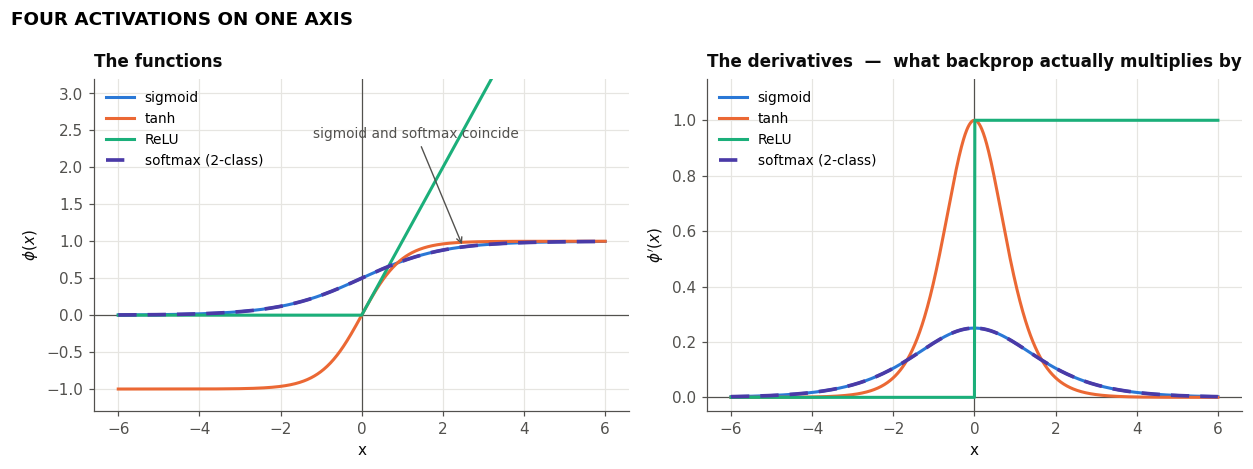

    x    sigmoid       tanh       ReLU  softmax (
-------------------------------------------------
   -4     0.0180    -0.9993     0.0000     0.0180
   -2     0.1192    -0.9640     0.0000     0.1192
   -1     0.2689    -0.7616     0.0000     0.2689
    0     0.5000     0.0000     0.0000     0.5000
    1     0.7311     0.7616     1.0000     0.7311
    2     0.8808     0.9640     2.0000     0.8808
    4     0.9820     0.9993     4.0000     0.9820


In [19]:
# --- 6.1 The four functions, and the four derivatives ---------------------
sm2   = lambda v: softmax(np.c_[v, np.zeros_like(v)], axis=1)[:, 0]
d_sm2 = lambda v: sm2(v) * (1 - sm2(v))

SERIES = [('sigmoid',            sigmoid, d_sigmoid, C['sigmoid'], '-'),
          ('tanh',               tanh,    d_tanh,    C['tanh'],    '-'),
          ('ReLU',               relu,    d_relu,    C['relu'],    '-'),
          ('softmax (2-class)',  sm2,     d_sm2,     C['softmax'], (0, (5, 3)))]

fig, ax = plt.subplots(1, 2, figsize=(11.4, 4.3))
for name, f, df, col, ls in SERIES:
    ax[0].plot(X, f(X), color=col, ls=ls, label=name, lw=2.4 if 'softmax' in name else 2.0)
    ax[1].plot(X, df(X), color=col, ls=ls, label=name, lw=2.4 if 'softmax' in name else 2.0)
ax[0].set_ylim(-1.3, 3.2); ax[1].set_ylim(-.05, 1.15)
ax[0].legend(fontsize=9, loc='upper left'); ax[1].legend(fontsize=9, loc='upper left')
ax[0].annotate('sigmoid and softmax coincide', (2.5, .92), (-1.2, 2.4), color=MUTE, fontsize=9,
               arrowprops=dict(arrowstyle='->', color=MUTE, lw=.9))
style(ax[0], 'The functions', ylabel=r'$\phi(x)$')
style(ax[1], "The derivatives  —  what backprop actually multiplies by", ylabel=r"$\phi'(x)$")
fig.suptitle('FOUR ACTIVATIONS ON ONE AXIS', x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

hdr = f'{"x":>5}' + ''.join(f'{n[:9]:>11}' for n, *_ in SERIES)
print(hdr); print('-' * len(hdr))
for x0 in (-4, -2, -1, 0, 1, 2, 4):
    v = np.array([float(x0)])
    print(f'{x0:>5}' + ''.join(f'{np.ravel(f(v))[0]:>11.4f}' for _, f, *_ in SERIES))

### 6.2 The experiment that settles the argument

A 20-layer network, 128 units wide, each activation given **its own correct
initialisation** (Xavier for sigmoid/tanh, He for ReLU — so this is a fair fight).
One forward pass, one backward pass. We record $\lVert \partial\mathcal{L}/\partial W_\ell\rVert$
at every layer.

**Read the plot right to left** — that is the direction the gradient travels.

 sigmoid:  layer 1 = 1.328e-14   layer 20 = 1.277e-01   ratio = 9,622,574,730,367x
    tanh:  layer 1 = 1.225e-02   layer 20 = 1.727e-02   ratio = 1x
    ReLU:  layer 1 = 1.541e+00   layer 20 = 3.638e+00   ratio = 2x


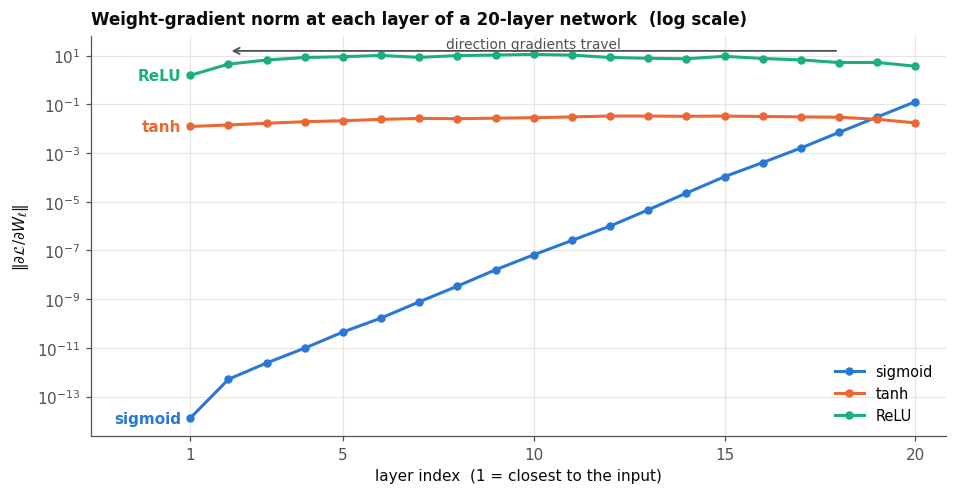

In [20]:
# --- 6.2 Gradient magnitude at every layer of a 20-layer network ----------
def gradient_flow(act, dact, gain, L=20, width=128, n=256, seed=0):
    rng = np.random.default_rng(seed)
    Ws = [rng.normal(0, np.sqrt(gain / width), size=(width, width)) for _ in range(L)]
    acts, zs = [rng.normal(size=(n, width))], []
    for W in Ws:
        z = acts[-1] @ W
        zs.append(z); acts.append(act(z))
    delta = 2 * acts[-1] / (n * width)                 # d/da of mean(a^2)
    gnorm = []
    for l in range(L - 1, -1, -1):
        dz = delta * dact(zs[l])
        gnorm.append(np.linalg.norm(acts[l].T @ dz))
        delta = dz @ Ws[l].T
    return np.array(gnorm[::-1])

runs = [('sigmoid', sigmoid, d_sigmoid, 1.0, C['sigmoid']),   # Xavier
        ('tanh',    tanh,    d_tanh,    1.0, C['tanh']),      # Xavier
        ('ReLU',    relu,    d_relu,    2.0, C['relu'])]      # He
L = 20
fig, ax = plt.subplots(figsize=(8.8, 4.6))
for name, f, df, gain, col in runs:
    g = gradient_flow(f, df, gain, L=L)
    ax.semilogy(np.arange(1, L + 1), g, color=col, marker='o', ms=4.5, label=name)
    ax.annotate(name, (0.75, g[0]), color=col, fontsize=10, fontweight='bold',
                ha='right', va='center')
    print(f'{name:>8}:  layer 1 = {g[0]:.3e}   layer {L} = {g[-1]:.3e}'
          f'   ratio = {g[-1] / g[0]:,.0f}x')
ax.set_xlim(-1.6, L + .8); ax.set_xticks([1, 5, 10, 15, 20])
ax.legend(fontsize=9.5, loc='lower right')
ax.annotate('', xy=(2, ax.get_ylim()[1] * .25), xytext=(18, ax.get_ylim()[1] * .25),
            arrowprops=dict(arrowstyle='->', color=MUTE, lw=1.2))
ax.text(10, ax.get_ylim()[1] * .34, 'direction gradients travel', color=MUTE,
        fontsize=9, ha='center')
style(ax, 'Weight-gradient norm at each layer of a 20-layer network  (log scale)',
      xlabel='layer index  (1 = closest to the input)',
      ylabel=r'$\|\partial\mathcal{L}/\partial W_\ell\|$', zero=False)
fig.tight_layout(); plt.show()

Sigmoid's early layers receive a gradient many orders of magnitude smaller than
its late layers: **the first half of the network is effectively frozen**. ReLU is close
to flat — every layer learns at a comparable rate.

**Tanh is flat here too** (ratio about 1×), and that is worth a second look, because §2.4
predicted decay. The difference is where the units operate. §2.4 assumed pre-activations
spread like $\mathcal{N}(0,1)$, so many units sat on the flat shoulders. With Xavier
initialisation the activations *shrink* layer by layer (§6.3 shows it), the units end up
near $x=0$ where $\tanh'\approx1$ (§6.3 measures an average slope of 0.97), and each layer
passes the gradient back almost unchanged. Sigmoid cannot do that: its slope is at most 0.25.
When the weights grow too large, tanh's units saturate and its average slope falls to about
0.08 (the "weights 10×" run in §6.3). So: **tanh's gradient suffers when its units saturate,
not automatically with depth.**

### 6.3 The other half of the story: the forward pass

Three measurements on a 20-layer stack, first with a correct initialisation and
then with **weights 10x too large** — which is both a plausible mis-tuning and a
fair model of what unchecked weight growth during training looks like.

1. **Centring.** Sigmoid's output mean is pinned near 0.5 at *every* depth: the
   conditioning problem of §2.5 never goes away. Tanh sits on 0. ReLU is positive
   by construction.
2. **Gradient multiplier**, $\mathbb{E}[\phi'(z)]$. Scale the weights up and the
   two bounded functions saturate — their multiplier drops by a factor of ~5-8.
   **ReLU's does not move at all**, because $\mathrm{ReLU}(cx)=c\,\mathrm{ReLU}(x)$
   for $c>0$: it is scale-equivariant, so its derivative distribution cannot be
   changed by rescaling the weights.
3. **But ReLU pays elsewhere.** It is unbounded above, so the same over-scaled
   weights make its activations *explode* — around $10^{19}$ by layer 20, where
   sigmoid and tanh simply sit against their ceilings. This is the trade: bounded
   activations die quietly, ReLU blows up loudly. It is why ReLU networks are
   paired with careful initialisation and normalisation layers.

> **Watch the tanh curve in the middle panel rise toward 1.0.** That is not good
> news. With Xavier init the activations shrink with depth, so tanh ends up
> operating in the small-$x$ region where it is *merely linear* — the network is
> quietly losing the non-linearity it was built for (§1.1).

            mean act  E[phi'] ok  E[phi'] x10    RMS act x10
  sigmoid      0.504       0.237        0.065       6.75e-01


     tanh     -0.001       0.972        0.083       9.57e-01
     ReLU      0.406       0.507        0.507       7.14e+19


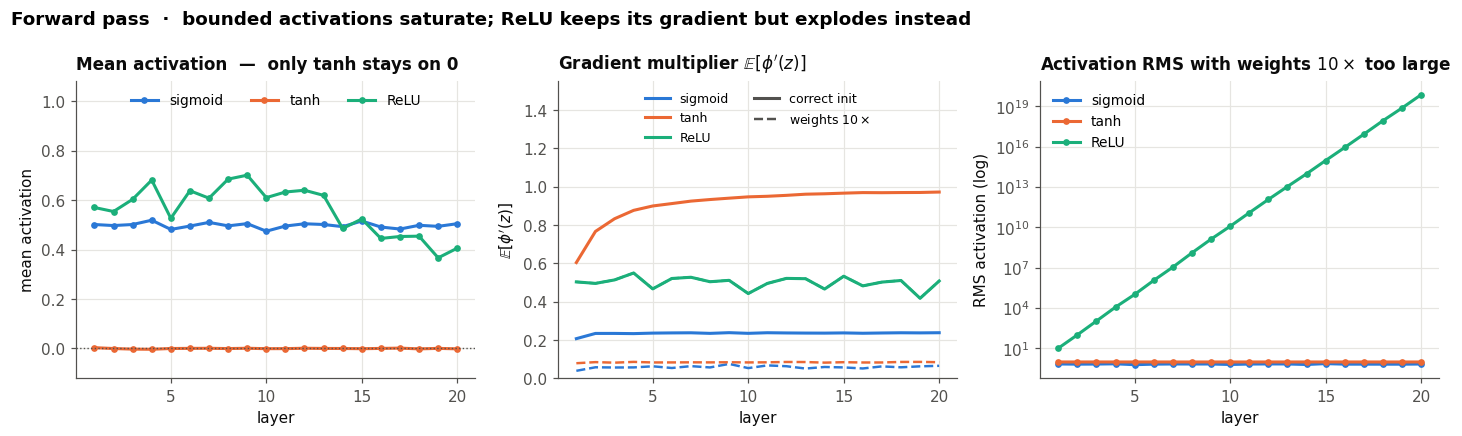

In [21]:
# --- 6.3 Centring, gradient multiplier, and activation scale vs depth -----
from matplotlib.lines import Line2D

def forward_probe(act, dact, gain, L=20, width=128, n=512, seed=1):
    rng = np.random.default_rng(seed)
    a, mean, dmean, rms = rng.normal(size=(n, width)), [], [], []
    for _ in range(L):
        W = rng.normal(0, np.sqrt(gain / width), size=(width, width))
        z = a @ W
        a = act(z)
        mean.append(a.mean()); dmean.append(dact(z).mean()); rms.append(np.sqrt((a ** 2).mean()))
    return map(np.array, (mean, dmean, rms))

CFG = [('sigmoid', sigmoid, d_sigmoid, 1.0, C['sigmoid']),   # Xavier
       ('tanh',    tanh,    d_tanh,    1.0, C['tanh']),      # Xavier
       ('ReLU',    relu,    d_relu,    2.0, C['relu'])]      # He
L, layers, BLOW = 20, np.arange(1, 21), 100.0               # BLOW: weights 10x larger

fig, ax = plt.subplots(1, 3, figsize=(13.2, 4.0))
print('{:>9}{:>11}{:>12}{:>13}{:>15}'.format(
    '', 'mean act', "E[phi'] ok", "E[phi'] x10", 'RMS act x10'))
with np.errstate(over='ignore', invalid='ignore'):
    for name, f, df, gain, col in CFG:
        m_ok, d_ok, _     = forward_probe(f, df, gain, L=L)
        _,    d_hi, r_hi  = forward_probe(f, df, gain * BLOW, L=L)
        ax[0].plot(layers, m_ok, color=col, marker='o', ms=3.4, label=name)
        ax[1].plot(layers, d_ok, color=col, lw=2.0)
        ax[1].plot(layers, d_hi, color=col, lw=1.6, ls='--')
        ax[2].semilogy(layers, r_hi, color=col, marker='o', ms=3.4, label=name)
        print(f'{name:>9}{m_ok[-1]:>11.3f}{d_ok[-1]:>12.3f}{d_hi[-1]:>13.3f}{r_hi[-1]:>15.2e}')

ax[0].axhline(0, color=MUTE, lw=.9, ls=':'); ax[0].set_ylim(-.12, 1.08)
ax[0].legend(fontsize=9, loc='upper center', ncol=3)
style(ax[0], 'Mean activation  —  only tanh stays on 0', xlabel='layer',
      ylabel='mean activation', zero=False)

ax[1].set_ylim(0, 1.55)
ax[1].legend(handles=[Line2D([], [], color=c, lw=2, label=n) for n, _, _, _, c in CFG] +
                     [Line2D([], [], color=MUTE, lw=2, label='correct init'),
                      Line2D([], [], color=MUTE, lw=1.6, ls='--', label=r'weights $10\times$')],
             fontsize=8.2, loc='upper center', ncol=2)
style(ax[1], r"Gradient multiplier $\mathbb{E}[\phi'(z)]$", xlabel='layer',
      ylabel=r"$\mathbb{E}[\phi'(z)]$", zero=False)

ax[2].legend(fontsize=9, loc='upper left')
style(ax[2], r'Activation RMS with weights $10\times$ too large', xlabel='layer',
      ylabel='RMS activation (log)', zero=False)
fig.suptitle('Forward pass  ·  bounded activations saturate; ReLU keeps its gradient but explodes instead',
             x=.005, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(); plt.show()

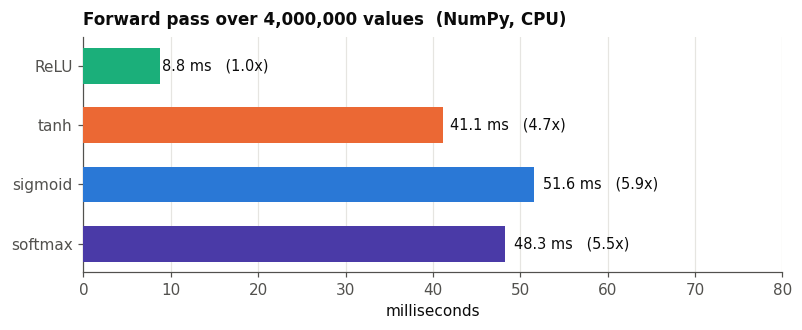

ReLU is a comparison. The others evaluate exp(). On a GPU the gap narrows,
but it is still free performance across billions of activations per step.


In [22]:
# --- 6.4 Forward-pass cost ------------------------------------------------
import time
big = np.random.default_rng(0).normal(size=(4_000_000,))
def bench(fn, reps=7):
    fn(big[:1000])                              # warm-up
    t = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(big); t.append(time.perf_counter() - t0)
    return min(t) * 1e3

# NOTE: we time the plain expressions, not our branch-masked stable sigmoid --
# the point is the cost of the MATH (compare vs exp vs exp+sum+divide).
rows = [('ReLU',    lambda v: np.maximum(0.0, v),        C['relu']),
        ('tanh',    lambda v: np.tanh(v),                C['tanh']),
        ('sigmoid', lambda v: 1.0 / (1.0 + np.exp(-v)),  C['sigmoid']),
        ('softmax', lambda v: softmax(v),                C['softmax'])]
times = [(n, bench(f), c) for n, f, c in rows]
base = min(t for _, t, _ in times)

fig, ax = plt.subplots(figsize=(7.4, 3.1))
names = [n for n, _, _ in times]
ax.barh(names, [t for _, t, _ in times], color=[c for _, _, c in times], height=.6, zorder=3)
for i, (n, t, _) in enumerate(times):
    ax.text(t * 1.02, i, f'{t:.1f} ms   ({t / base:.1f}x)', va='center', fontsize=9.5, color=INK)
ax.invert_yaxis(); ax.set_xlim(0, max(t for _, t, _ in times) * 1.55)
ax.grid(axis='y', visible=False)
style(ax, 'Forward pass over 4,000,000 values  (NumPy, CPU)', xlabel='milliseconds',
      ylabel=None, zero=False)
fig.tight_layout(); plt.show()
print('ReLU is a comparison. The others evaluate exp(). On a GPU the gap narrows,')
print('but it is still free performance across billions of activations per step.')

### 6.5 Summary table

| | **Sigmoid** | **Tanh** | **ReLU** | **Softmax** |
|---|---|---|---|---|
| Formula | $\dfrac{1}{1+e^{-x}}$ | $\dfrac{e^{x}-e^{-x}}{e^{x}+e^{-x}}$ | $\max(0,x)$ | $\dfrac{e^{z_i}}{\sum_j e^{z_j}}$ |
| Range | $(0,1)$ | $(-1,1)$ | $[0,\infty)$ | $(0,1)$, sums to 1 |
| Derivative | $\sigma(1-\sigma)$ | $1-\tanh^2$ | $\mathbb{1}[x>0]$ | $p_i(\delta_{ij}-p_j)$ |
| Max derivative | **0.25** | **1.0** | **1.0** | 0.25 (diagonal) |
| Zero-centred | ✗ | ✓ | ✗ | ✗ |
| Saturates | both sides | both sides | negative only (hard) | — |
| Vanishing gradient | **severe** | moderate | no (on active path) | no (with CE) |
| Element-wise | ✓ | ✓ | ✓ | ✗ — couples all $K$ |
| Cost | `exp` + div | 2 `exp` | compare | $O(K)$ `exp` + sum |
| Sparse output | ✗ | ✗ | ✓ (~50% zeros) | ✗ |
| Main failure | vanishing gradient | vanishing gradient | dying units | wrong for multi-label |
| Typical home | binary / multi-label **output**, gates | RNN cells, bounded regression | **hidden layers** | multi-class **output**, attention |

---
## 7 · Decision guide

### 7.1 Output layer — determined by the task, never by taste

| Task | Output activation | Loss | Why |
|---|---|---|---|
| Binary classification | **1 × sigmoid** | binary cross-entropy | one probability is all you need (§5.6) |
| Multi-class, **exclusive** | **softmax** over $K$ | categorical cross-entropy | classes must compete and sum to 1 |
| **Multi-label** (many can be true) | **$K$ × sigmoid** | BCE, summed over labels | labels are independent |
| Regression, unbounded | **none (linear)** | MSE / Huber | squashing would cap the range |
| Regression, $[0,\infty)$ | **softplus** (or ReLU) | MSE / Poisson | counts, durations, intensities; softplus never gets stuck at 0 |
| Regression, $[-1,1]$ | **tanh** | MSE | normalised audio, angles, control signals |
| Regression, $[0,1]$ | **sigmoid** | MSE / BCE | a ratio or a fraction |
| Attention weights | **softmax** over keys | (part of the layer) | competition is the mechanism |
| Gates (LSTM/GRU) | **sigmoid** | (part of the cell) | $(0,1)$ literally means "how much passes" |

### 7.2 Hidden layers — a short flowchart

1. **Start with ReLU.** It is the right answer for CNNs and MLPs the large majority of the time.
2. Building a **transformer**? Use **GELU** (or SiLU). It is the field default and costs little.
3. Building an **RNN/LSTM/GRU**? Use **tanh** for the state and **sigmoid** for the gates — the bounded range is what keeps the recurrence stable.
4. Diagnosed **>90% dead units** (§4.4)? Switch to **Leaky ReLU / ELU**, *and* lower your learning rate — the LR is usually the real cause.
5. Training **very deep without normalisation**? Prefer **ELU** or **SELU**, which self-centre the activations.
6. **Never** use sigmoid on a hidden layer. There is no situation in 2026 where it is the right choice.

### 7.3 Five errors this lab exists to prevent

| Mistake | What actually happens | Fix |
|---|---|---|
| Sigmoid on hidden layers of a deep net | early layers never train (§6.2) | ReLU |
| Softmax on a multi-label problem | model cannot assign high probability to two true labels | per-label sigmoid |
| Softmax **and** `from_logits=True` | softmax applied twice; gradients wrong and tiny | pass raw logits, let the loss do it |
| Learning rate too high with ReLU | units die permanently, accuracy collapses to chance (§4.3) | lower LR, or Leaky ReLU |
| Naive `exp(z)/sum(exp(z))` | `inf` / `nan` on large logits (§5.3) | subtract the max |

### 7.4 One-line summary

> **ReLU (or GELU) in the hidden layers; the task picks the output layer;
> tanh only inside recurrences; sigmoid only for gates and per-label probabilities.**

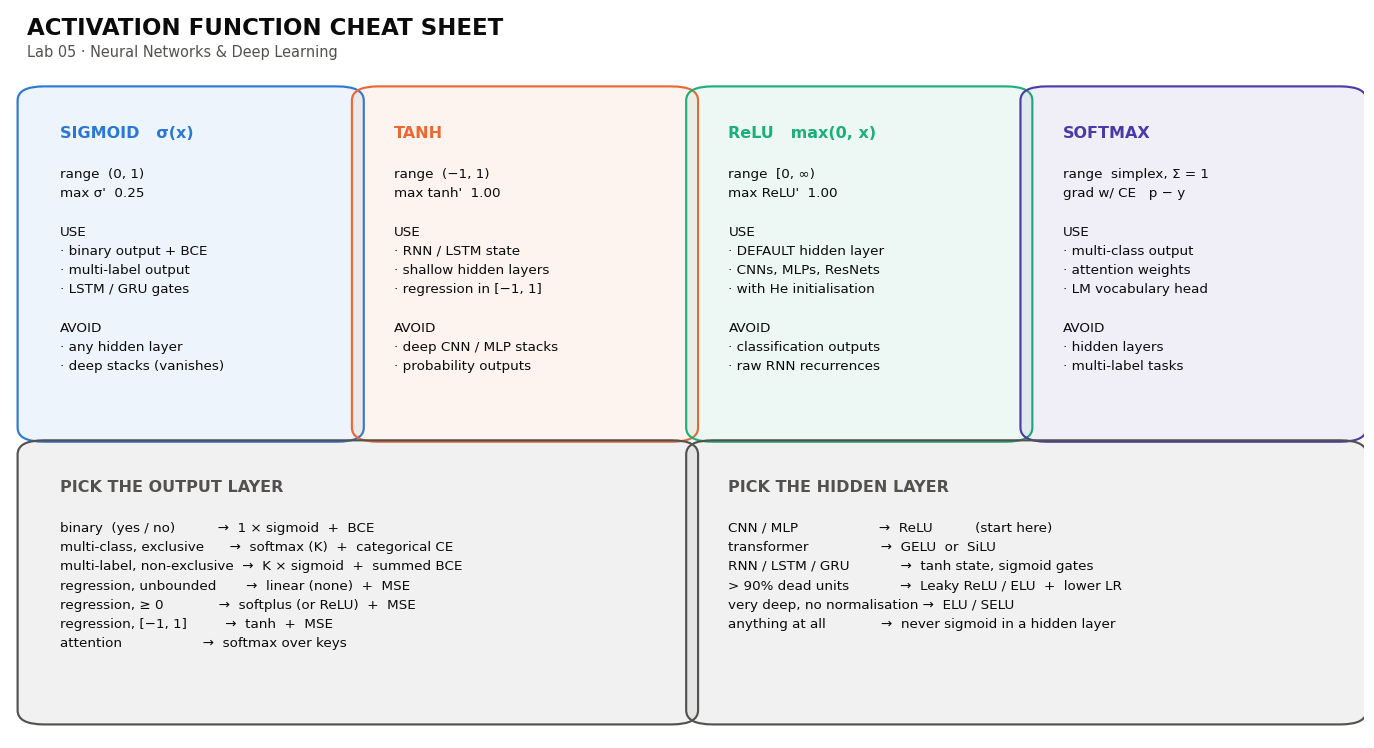

In [23]:
# --- 7.5 The cheat sheet, as a printable card -----------------------------
from matplotlib.patches import FancyBboxPatch

def card(ax, x, y, w, h, title, body, col):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.012,rounding_size=0.02',
                                linewidth=1.4, edgecolor=col, facecolor=col + '14'))
    ax.text(x + .020, y + h - .045, title, fontsize=10.5, fontweight='bold', color=col, va='top')
    ax.text(x + .020, y + h - .105, body, fontsize=8.8, color=INK, va='top', linespacing=1.62)

fig, ax = plt.subplots(figsize=(12.6, 6.9))
ax.set_xlim(-.012, 1.012); ax.set_ylim(-.02, 1.02); ax.axis('off')
ax.text(0, 1.012, 'ACTIVATION FUNCTION CHEAT SHEET', fontsize=15, fontweight='bold', color=INK, va='top')
ax.text(0, .972, 'Lab 05 · Neural Networks & Deep Learning', fontsize=9.5, color=MUTE, va='top')

card(ax, 0.005, .415, .238, .485, 'SIGMOID   σ(x)',
     'range  (0, 1)\n'
     "max σ'  0.25\n\n"
     'USE\n'
     '· binary output + BCE\n'
     '· multi-label output\n'
     '· LSTM / GRU gates\n\n'
     'AVOID\n'
     '· any hidden layer\n'
     '· deep stacks (vanishes)', C['sigmoid'])

card(ax, 0.258, .415, .238, .485, 'TANH',
     'range  (−1, 1)\n'
     "max tanh'  1.00\n\n"
     'USE\n'
     '· RNN / LSTM state\n'
     '· shallow hidden layers\n'
     '· regression in [−1, 1]\n\n'
     'AVOID\n'
     '· deep CNN / MLP stacks\n'
     '· probability outputs', C['tanh'])

card(ax, 0.511, .415, .238, .485, 'ReLU   max(0, x)',
     'range  [0, ∞)\n'
     "max ReLU'  1.00\n\n"
     'USE\n'
     '· DEFAULT hidden layer\n'
     '· CNNs, MLPs, ResNets\n'
     '· with He initialisation\n\n'
     'AVOID\n'
     '· classification outputs\n'
     '· raw RNN recurrences', C['relu'])

card(ax, 0.764, .415, .238, .485, 'SOFTMAX',
     'range  simplex, Σ = 1\n'
     "grad w/ CE   p − y\n\n"
     'USE\n'
     '· multi-class output\n'
     '· attention weights\n'
     '· LM vocabulary head\n\n'
     'AVOID\n'
     '· hidden layers\n'
     '· multi-label tasks', C['softmax'])

card(ax, 0.005, .010, .491, .383, 'PICK THE OUTPUT LAYER',
     'binary  (yes / no)          →  1 × sigmoid  +  BCE\n'
     'multi-class, exclusive      →  softmax (K)  +  categorical CE\n'
     'multi-label, non-exclusive  →  K × sigmoid  +  summed BCE\n'
     'regression, unbounded       →  linear (none)  +  MSE\n'
     'regression, ≥ 0             →  softplus (or ReLU)  +  MSE\n'
     'regression, [−1, 1]         →  tanh  +  MSE\n'
     'attention                   →  softmax over keys', MUTE)

card(ax, 0.511, .010, .491, .383, 'PICK THE HIDDEN LAYER',
     'CNN / MLP                   →  ReLU          (start here)\n'
     'transformer                 →  GELU  or  SiLU\n'
     'RNN / LSTM / GRU            →  tanh state, sigmoid gates\n'
     '> 90% dead units            →  Leaky ReLU / ELU  +  lower LR\n'
     'very deep, no normalisation →  ELU / SELU\n'
     'anything at all             →  never sigmoid in a hidden layer', MUTE)

fig.tight_layout(); plt.show()

---
## 8 · Exercises

**E1 — Derive.** Show $\sigma'(x)=\sigma(x)(1-\sigma(x))$ from the quotient rule,
then use $\tanh(x)=2\sigma(2x)-1$ to derive $\tanh'(x)=1-\tanh^2(x)$. Confirm both
against the §3.1 cell.

**E2 — Predict, then measure.** Before running anything: at what depth does the
*typical* tanh curve in §2.4 fall below `float32` epsilon ($1.2\times10^{-7}$)? Extend
`depths` and check. Then explain why the real 20-layer network in §6.2 shows almost no
decay for tanh (hint: compare tanh's $\mathbb{E}[\phi'(z)]$ in §6.3 with correct and with 10× weights).

**E3 — Break a network on purpose.** In §4.3, set the learning rate so that
*exactly* 50% of the units die. Now re-run with `leaky` in place of `relu` in
`train_relu_mlp`. Does the accuracy recover? Explain in one sentence why.

**E4 — Multi-label.** Build a 3-label toy problem where two labels are true at
once. Train two heads — softmax and per-label sigmoid — and plot the predicted
probabilities. Show numerically that the softmax head *cannot* give both true
labels a probability above 0.5.

**E5 — Temperature.** Take the §5.4 logits. Find the temperature $T$ at which the
output entropy equals exactly half the uniform entropy $\ln K$. Solve it with
`scipy.optimize.brentq`.

**E6 — Extend the notebook.** Add **Softplus** $\log(1+e^{x})$ and **Mish**
$x\tanh(\text{softplus}(x))$ to the §4.5 family plot, with analytic derivatives.
Which one is closest to GELU, and where do they differ most?

**E7 — Back to Lab 02.** Take your MNIST network. Replace ReLU with sigmoid in
every hidden layer, keep everything else identical, and train both for 5 epochs.
Report the validation-accuracy curves side by side and explain the gap using the
§6.2 plot.

---

### References

- Glorot & Bengio (2010), *Understanding the difficulty of training deep feedforward neural networks* — Xavier initialisation, the saturation analysis.
- Nair & Hinton (2010), *Rectified linear units improve restricted Boltzmann machines* — ReLU.
- Krizhevsky, Sutskever & Hinton (2012), *ImageNet classification with deep CNNs* — ReLU at scale.
- He et al. (2015), *Delving deep into rectifiers* — PReLU and He initialisation.
- Clevert et al. (2016), *Fast and accurate deep network learning by ELUs*.
- Hendrycks & Gimpel (2016), *Gaussian Error Linear Units (GELUs)*.
- Ramachandran et al. (2017), *Searching for activation functions* — Swish/SiLU.
- Hinton, Vinyals & Dean (2015), *Distilling the knowledge in a neural network* — temperature.

*Lab 05 · Neural Networks & Deep Learning · 2026*